In [51]:
# 1.1 Setup: imports, paths, display options
%load_ext autoreload
%autoreload 2

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model                  # only to cross-check our GJR fits (Steps 3.1, 4.3)

# Hide library deprecation notices (pandas 3 / yfinance "inplace", "sort" ...): they are about future
# versions of the libraries, not about our results. Real errors and data problems are still shown.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
try:
    from pandas.errors import Pandas4Warning
    warnings.filterwarnings("ignore", category=Pandas4Warning)
except ImportError:                          # older pandas: the class does not exist
    pass

ROOT = Path.cwd().parent                     # project folder (the notebook is in notebooks/)
sys.path.insert(0, str(ROOT / "src"))        # so that "import riskreport" works

# package imports: always AFTER sys.path.insert
from riskreport.config import load_config, asset_table
from riskreport.data import (load_yahoo, load_fred, history_summary, build_eurusd, eur_returns,
                             mask_stale, quality_checks, factor_returns, eur_from_factors)
from riskreport.portfolio import put_market, fund_history
from riskreport.pricing import bs_put, bs_put_delta
from riskreport.models import (gjr_variance, fit_gjr, fit_gjr_all, ljung_box,
                               dcc_filter, dcc_negloglik, fit_dcc)
from riskreport.risk import (filtered_shocks, fhs_scenarios, simulate_paths, compound_paths,
                             scenario_pnl, var_es, pnl_contributions, euler_decomposition)
from riskreport.evt import fit_gpd, gpd_var_es, evt_var_es
from riskreport.stress import window_factor_moves, hypothetical_moves
from riskreport.engine import METHODS, rolling_risk
from riskreport.backtest import backtest_table, z2_critical, traffic_light
from riskreport.daily import fit_models, evening_risk, var_of_positions
from riskreport.limits import limit_table, vol_drivers, commentary
from riskreport.report import fig_to_base64, render_report, save_report
from riskreport.plots import plot_risk_history, plot_risk_budget, plot_var_backtest

CONFIG = ROOT / "config" / "config.yaml"
RAW = ROOT / "data" / "raw"                  # downloads
OUT = ROOT / "data" / "processed"            # results we compute
FIGURES = ROOT / "reports" / "figures"       # charts for the Word report
DOCS = ROOT / "docs" / "reports"             # daily HTML reports (GitHub Pages)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

for p in [CONFIG, RAW, OUT, FIGURES, DOCS]:
    print(f"{str(p):80s} exists: {p.exists()}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\config\config.yaml exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\data\raw exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\data\processed exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\reports\figures exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\docs\reports exists: True


In [2]:
# 1.2 Load the configuration and check it
cfg = load_config(CONFIG)
assets = asset_table(cfg)
print(f"{cfg['fund']['name']}, NAV EUR {cfg['fund']['nav']:,.0f}, base {cfg['fund']['base_currency']}")
print(assets[["ticker", "currency", "asset_class", "weight", "duration", "spread_duration"]].to_string())
print(f"\nWeights sum to {assets['weight'].sum():.4f}")
print("By asset class:")
print(assets.groupby("asset_class")["weight"].sum().to_string())
print(f"USD exposure (unhedged): {assets.loc[assets['currency'] == 'USD', 'weight'].sum():.1%}")

# validation: a broken config must be rejected
import copy, yaml, tempfile
bad = copy.deepcopy(cfg)
bad["assets"]["us_equity"]["weight"] = 0.15            # weights now sum to 0.95
with tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False) as f:
    yaml.safe_dump(bad, f)
try:
    load_config(f.name)
except ValueError as e:
    print(f"\nBroken config correctly rejected: {e}")

Global Multi-Asset Fund (EUR), NAV EUR 100,000,000, base EUR
              ticker currency  asset_class  weight  duration  spread_duration
euro_equity  EXW1.DE      EUR       Equity   0.150       NaN              NaN
us_equity        SPY      USD       Equity   0.200       NaN              NaN
em_equity        EEM      USD       Equity   0.100       NaN              NaN
euro_govt    EUNH.DE      EUR        Rates   0.250       7.3              NaN
euro_ig      EUN5.DE      EUR       Credit   0.125       4.6              4.6
us_hy            HYG      USD       Credit   0.050       3.0              3.0
gold             GLD      USD  Commodities   0.075       NaN              NaN
commodities      DBC      USD  Commodities   0.050       NaN              NaN

Weights sum to 1.0000
By asset class:
asset_class
Commodities    0.125
Credit         0.175
Equity         0.450
Rates          0.250
USD exposure (unhedged): 47.5%

Broken config correctly rejected: config: target weights sum to 0.9500

In [3]:
# 1.3 Download the candidate tickers (with alternatives for the European ETFs) and FRED series; compare histories
start = cfg["fund"]["start"]
candidates = {
    "euro_equity": ["EXW1.DE", "EUNK.DE", "CSX5.AS"],    # EURO STOXX 50 / Europe equity ETFs
    "us_equity":   ["SPY"],
    "em_equity":   ["EEM"],
    "euro_govt":   ["IEGA.AS", "EUNH.DE", "IEGA.L"],     # iShares Core EUR Govt Bond
    "euro_ig":     ["IEAC.AS", "EUN5.DE", "IEAC.L"],     # iShares Core EUR Corp Bond
    "us_hy":       ["HYG"],
    "gold":        ["GLD"],
    "commodities": ["DBC"],
}
all_tickers = [t for ts in candidates.values() for t in ts]
px_test = load_yahoo(all_tickers, start=start)

summary = history_summary(px_test)
summary.insert(0, "asset", [k for k, ts in candidates.items() for _ in ts])
print("Yahoo (adjusted close):")
print(summary.to_string())

fred_test = pd.concat([load_fred(code, start) for code in cfg["fred"].values()], axis=1)
print("\nFRED:")
print(history_summary(fred_test).to_string())
print(f"\nLast values: {fred_test.ffill().iloc[-1].round(3).to_dict()}")

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: IEGA.L"}}}
$IEGA.L: possibly delisted; no timezone found

1 Failed download:
['IEGA.L']: possibly delisted; no timezone found


Yahoo (adjusted close):
               asset       first        last prices years longest gap (days) unchanged days %
EXW1.DE  euro_equity  2008-01-02  2026-10-28   4781  18.8                  6             1.09
EUNK.DE  euro_equity  2009-10-20  2026-10-28   4252  17.0                  7             1.74
CSX5.AS  euro_equity  2014-04-28  2026-10-28   3199  12.5                  5             0.63
SPY        us_equity  2005-01-03  2026-10-28   5490  21.8                  5             0.29
EEM        em_equity  2005-01-03  2026-10-28   5490  21.8                  5             0.66
IEGA.AS    euro_govt  2014-06-06  2026-10-28   3162  12.4                  5             1.17
EUNH.DE    euro_govt  2009-04-17  2026-10-28   4455  17.5                  6             1.14
IEGA.L     euro_govt         NaN         NaN    0.0   NaN                NaN              NaN
IEAC.AS      euro_ig  2009-05-06  2026-10-28   4475  17.5                  5             2.21
EUN5.DE      euro_ig  2009-05-26  20

In [4]:
# 1.4 Final data: download, cross-check Yahoo against FRED, save the raw files
cfg = load_config(CONFIG)                                   # re-read: tickers changed
assets = asset_table(cfg)
start = cfg["fund"]["start"]

prices = load_yahoo(list(assets["ticker"]), start=start)
prices.columns = assets.index                              # name columns by asset key
market = load_yahoo(list(cfg["market"].values()), start=start)
market.columns = list(cfg["market"].keys())                # eurusd, vix, index
fred = pd.concat([load_fred(code, start) for code in cfg["fred"].values()], axis=1, sort=True)
fred.columns = list(cfg["fred"].keys())                    # rate_3m, eurusd_check, vix_check

# cross-check on common days
for name, y, f in [("EUR/USD", market["eurusd"], fred["eurusd_check"]), ("VIX", market["vix"], fred["vix_check"])]:
    both = pd.concat([y, f], axis=1, keys=["yahoo", "fred"]).dropna()
    diff = both["yahoo"] - both["fred"]
    d_ret = np.log(both).diff().dropna()
    w_ret = np.log(both.resample("W-FRI").last()).diff().dropna()
    worst = diff.abs().idxmax()
    print(f"{name}: {len(both):,} common days | median |diff| {diff.abs().median():.4f} | "
          f"corr daily changes {d_ret.corr().iloc[0, 1]:.3f}, weekly {w_ret.corr().iloc[0, 1]:.3f} | "
          f"largest gap {diff.loc[worst]:+.4f} on {worst.date()} (yahoo {both.loc[worst, 'yahoo']:.4f}, fred {both.loc[worst, 'fred']:.4f})")

print(f"\nLast dates: prices {prices.index[-1].date()}, market {market.dropna().index[-1].date()}, "
      f"T-bill {fred['rate_3m'].dropna().index[-1].date()}")
print(history_summary(pd.concat([prices, market], axis=1)).to_string())

prices.to_csv(RAW / "prices.csv")
market.to_csv(RAW / "market.csv")
fred.to_csv(RAW / "fred.csv")
print("\nSaved data/raw/prices.csv, market.csv, fred.csv")

EUR/USD: 5,435 common days | median |diff| 0.0026 | corr daily changes 0.370, weekly 0.837 | largest gap +0.1976 on 2008-12-08 (yahoo 1.4918, fred 1.2942)
VIX: 5,491 common days | median |diff| 0.0000 | corr daily changes 0.999, weekly 0.999 | largest gap +2.6100 on 2026-02-06 (yahoo 20.3700, fred 17.7600)

Last dates: prices 2026-10-28, market 2026-10-28, T-bill 2026-10-26
                  first        last prices years longest gap (days) unchanged days %
euro_equity  2008-01-02  2026-10-28   4781  18.8                  6             1.09
us_equity    2005-01-03  2026-10-28   5490  21.8                  5             0.29
em_equity    2005-01-03  2026-10-28   5490  21.8                  5             0.66
euro_govt    2009-04-17  2026-10-28   4455  17.5                  6             1.14
euro_ig      2009-05-26  2026-10-28   4425  17.4                  6             1.76
us_hy        2007-04-11  2026-10-28   4920  19.5                  5             1.52
gold         2005-01-03  202

In [5]:
# 1.5 Diagnose Yahoo's EUR/USD against FRED: bad prints, date alignment, gaps
y, f = market["eurusd"], fred["eurusd_check"]
both = pd.concat([y, f], axis=1, keys=["yahoo", "fred"]).dropna()
gap = (both["yahoo"] / both["fred"] - 1)                          # relative level difference

# (a) the 10 largest disagreements
print("Largest disagreements (Yahoo vs FRED level):")
print((100 * gap).abs().nlargest(10).round(2).rename("|diff| %").to_frame()
      .join(both).to_string())
bad = gap.abs() > 0.02                                             # more than 2% apart = a bad print
print(f"\nDays more than 2% apart: {bad.sum()} ({bad.mean():.2%}) - years: "
      f"{sorted(set(both.index[bad].year))}")

# (b) date alignment: correlation of daily changes with FRED shifted by -1, 0, +1 day
ry = np.log(both["yahoo"]).diff()
rf = np.log(both["fred"]).diff()
keep = ~(bad | bad.shift(1, fill_value=False))                     # drop bad days and the day after
print("\nCorrelation of daily changes (bad days removed):")
for lag in (-1, 0, 1):
    print(f"  Yahoo(t) vs FRED(t{lag:+d}): {ry[keep].corr(rf.shift(-lag)[keep]):.3f}")

# (c) gaps in Yahoo's series longer than 4 calendar days
ys = y.dropna()
g = ys.index.to_series().diff().dt.days
print("\nYahoo EUR/USD gaps > 4 days:")
print(pd.DataFrame({"from": ys.index[ys.index.get_indexer(g[g > 4].index) - 1].date,
                    "to": g[g > 4].index.date, "days": g[g > 4].values}).to_string(index=False))

# (d) weekly correlation without bad days
wk = both[~bad].resample("W-FRI").last()
print(f"\nWeekly correlation without bad days: {np.log(wk).diff().corr().iloc[0, 1]:.3f}")

Largest disagreements (Yahoo vs FRED level):
            |diff| %     yahoo    fred
date                                  
2008-12-08     15.27  1.491803  1.2942
2008-10-08      9.34  1.495707  1.3680
2008-02-08      7.35  1.557099  1.4505
2008-09-08      6.54  1.505004  1.4126
2008-01-08      5.80  1.557099  1.4717
2009-03-18      2.85  1.348399  1.3110
2008-10-28      2.67  1.280902  1.2476
2015-12-03      2.65  1.061301  1.0902
2020-03-19      2.45  1.096155  1.0699
2010-08-11      2.22  1.318496  1.2899

Days more than 2% apart: 15 (0.28%) - years: [2008, 2009, 2010, 2011, 2015, 2020, 2025]

Correlation of daily changes (bad days removed):
  Yahoo(t) vs FRED(t-1): 0.498
  Yahoo(t) vs FRED(t+0): 0.442
  Yahoo(t) vs FRED(t+1): 0.063

Yahoo EUR/USD gaps > 4 days:
      from         to  days
2008-07-31 2008-08-08   8.0
2008-08-08 2008-08-26  18.0
2025-04-17 2025-04-22   5.0

Weekly correlation without bad days: 0.867


In [6]:
# 1.6 Build the EUR/USD series: FRED + Yahoo for the days FRED has not published yet
eurusd, fx_prov = build_eurusd(fred["eurusd_check"], market["eurusd"])
print(f"EUR/USD: {len(eurusd):,} days, {eurusd.index[0].date()} to {eurusd.index[-1].date()}; "
      f"provisional days: {fx_prov.sum()}")
print(pd.concat([eurusd, fx_prov, fred["eurusd_check"].rename("fred"), market["eurusd"].rename("yahoo")],
                axis=1, sort=True).loc[eurusd.index[-8]:].round(4).to_string())

# the 2008 bad prints are gone: compare with FRED on the worst Yahoo day
d = pd.Timestamp("2008-12-08")
print(f"\n{d.date()}: series {eurusd.loc[d]:.4f}, FRED {fred.loc[d, 'eurusd_check']:.4f}, Yahoo {market.loc[d, 'eurusd']:.4f}")
print(f"Largest daily move in the series: {np.log(eurusd).diff().abs().max():.2%} "
      f"on {np.log(eurusd).diff().abs().idxmax().date()}")

# validation: a bad Yahoo print after FRED's last date must be rejected
bad_y = market["eurusd"].copy()
bad_y.loc[bad_y.index > fred["eurusd_check"].dropna().index[-1]] *= 1.10
try:
    build_eurusd(fred["eurusd_check"], bad_y)
except ValueError as e:
    print(f"\nBad print correctly rejected: {e}")

eurusd.to_frame().join(fx_prov).to_csv(OUT / "eurusd.csv")
print("Saved data/processed/eurusd.csv")

EUR/USD: 5,468 days, 2005-01-03 to 2026-10-28; provisional days: 3
            eurusd provisional    fred   yahoo
date                                          
2026-10-19  1.1209       False  1.1209  1.1225
2026-10-20  1.1232       False  1.1232  1.1216
2026-10-21  1.1219       False  1.1219  1.1227
2026-10-22  1.1212       False  1.1212  1.1235
2026-10-23  1.1199       False  1.1199  1.1221
2026-10-26  1.1218        True     NaN  1.1218
2026-10-27  1.1174        True     NaN  1.1174
2026-10-28  1.1140        True     NaN  1.1140

2008-12-08: series 1.2942, FRED 1.2942, Yahoo 1.4918
Largest daily move in the series: 4.62% on 2009-03-19

Bad print correctly rejected: EUR/USD: Yahoo 1.2339 on 2026-10-26 vs FRED 1.1199 on 2026-10-23 (+10.18% > 1%): suspected bad print
Saved data/processed/eurusd.csv


In [7]:
# 1.7 Daily returns in EUR on the fund's calendar (Equation 1), with checks
rets, info = eur_returns(prices, eurusd, assets["currency"])
print(f"Returns in EUR: {info['days']:,} days, {info['start']} to {info['end']}; "
      f"days skipped (a market closed): {info['dropped']}; EUR/USD carried forward on {info['fx_filled']} days")
print(f"Missing values: {int(rets.isna().sum().sum())}")

# (1) Equation 1 by hand for SPY on one day
d = rets.index[-1]
dp = rets.index[-2]
r_usd = prices.loc[d, "us_equity"] / prices.loc[dp, "us_equity"] - 1
x0, x1 = eurusd.asof(dp), eurusd.asof(d)
print(f"\nSPY on {d.date()}: USD return {r_usd:+.4%}, EUR/USD {x0:.4f} -> {x1:.4f}, "
      f"Equation 1 {(1 + r_usd) * x0 / x1 - 1:+.4%}, table {rets.loc[d, 'us_equity']:+.4%}")

# (2) volatility in EUR vs in local currency, and the FX effect
loc_rets = prices.loc[rets.index[0] - pd.Timedelta(days=10):].dropna(how="any").pct_change().loc[rets.index]
tab = pd.DataFrame({"currency": assets["currency"],
                    "vol local % (ann.)": 100 * np.sqrt(252) * loc_rets.std(),
                    "vol EUR % (ann.)": 100 * np.sqrt(252) * rets.std(),
                    "mean EUR % (ann.)": 100 * 252 * rets.mean(),
                    "worst day EUR %": 100 * rets.min(),
                    "worst date": rets.idxmin().dt.date,
                    "best day EUR %": 100 * rets.max()})
print("\n" + tab.round(2).to_string())
fx_ret = eurusd.reindex(rets.index, method="ffill").pct_change()
print(f"\nEUR/USD: vol {100 * np.sqrt(252) * fx_ret.std():.2f}% a year; "
      f"correlation of SPY in USD with EUR/USD changes: {loc_rets['us_equity'].corr(fx_ret):+.2f}")

# (3) days skipped per year (holidays of one market)
all_days = prices.loc[rets.index[0]:].notna().any(axis=1)
skipped = all_days[all_days].index.difference(rets.index)
print("\nDays skipped per year:", skipped.year.value_counts().sort_index().to_dict())

rets.to_csv(OUT / "returns_eur.csv")
print("\nSaved data/processed/returns_eur.csv")

Returns in EUR: 4,309 days, 2009-05-27 to 2026-10-28; days skipped (a market closed): 190; EUR/USD carried forward on 40 days
Missing values: 0

SPY on 2026-10-28: USD return +0.1377%, EUR/USD 1.1174 -> 1.1140, Equation 1 +0.4454%, table +0.4454%

            currency  vol local % (ann.)  vol EUR % (ann.)  mean EUR % (ann.)  worst day EUR %  worst date  best day EUR %
euro_equity      EUR               20.05             20.05               9.77           -11.97  2020-03-12           11.01
us_equity        USD               17.10             17.64              17.19           -11.53  2020-03-16            9.22
em_equity        USD               22.10             21.16               9.66           -13.05  2020-03-16            8.53
euro_govt        EUR                5.03              5.03               1.37            -2.70  2020-03-18            2.84
euro_ig          EUR                4.16              4.16               1.95            -4.84  2020-03-18            2.96
us_hy         

In [8]:
# 1.8 Data-quality checks: reversed outliers (vol-scaled) and stale prices, then a test with an injected error
suspects, stale = quality_checks(rets)
print(f"Suspect data errors (|z| > 6 and reversed > 80% the next day): {len(suspects)}")
if len(suspects):
    print(suspects.round(2).to_string(index=False))
print("\nStale prices (longest run of zero returns):")
print(stale.to_string())

# the extreme days found in 1.7: real moves or errors? Their size in vol units and the next day
print("\nExtreme days in context:")
for a, d in [("gold", "2026-01-30"), ("euro_equity", "2020-03-12"), ("commodities", "2022-03-09")]:
    i = rets.index.get_loc(pd.Timestamp(d))
    vol = rets[a].iloc[i - 60:i].std()
    print(f"  {a:12s} {d}: {100 * rets[a].iloc[i]:+.2f}% = {rets[a].iloc[i] / vol:+.1f} x vol before "
          f"({100 * vol:.2f}%); next day {100 * rets[a].iloc[i + 1]:+.2f}%")

# validation: inject a bad close in euro_govt and check it is caught
test = rets.copy()
d0 = test.index[2000]
test.loc[d0, "euro_govt"] = -0.04                              # a fake -4% day ...
test.loc[test.index[2001], "euro_govt"] = 0.04 / 0.96          # ... fully reversed the next day
found, _ = quality_checks(test)
print(f"\nInjected error on {d0.date()} found: {((found['asset'] == 'euro_govt') & (found['date'] == d0.date())).any()}")

Suspect data errors (|z| > 6 and reversed > 80% the next day): 1
  asset       date  return %  next day %  vol before %     z   status
euro_ig 2026-03-03      -0.7        0.65          0.11 -6.17 TO CHECK

Stale prices (longest run of zero returns):
            longest zero run        ends   flag
euro_equity                3  2023-12-06   True
us_equity                  1  2018-10-08  False
em_equity                  0        None  False
euro_govt                  3  2023-12-06   True
euro_ig                    3  2023-12-06   True
us_hy                      1  2014-08-21  False
gold                       0        None  False
commodities                1  2014-10-13  False

Extreme days in context:
  gold         2026-01-30: -9.84% = -8.0 x vol before (1.23%); next day -3.37%
  euro_equity  2020-03-12: -11.97% = -7.2 x vol before (1.67%); next day +1.58%
  commodities  2022-03-09: -9.51% = -6.6 x vol before (1.43%); next day -0.64%

Injected error on 2017-06-26 found: True


In [9]:
# 1.9 Inspect the two suspicious periods: raw prices and returns of every asset
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
for label, a, b in [("euro_ig, 3 Mar 2026", "2026-02-26", "2026-03-09"),
                    ("Xetra ETFs, Dec 2023", "2023-11-28", "2023-12-12")]:
    print(f"\n=== {label} ===")
    print("Raw prices (local currency):")
    print(prices.loc[a:b].to_string())
    print("\nReturns in EUR (%):")
    print((100 * rets.loc[a:b]).round(3).to_string())
pd.reset_option("display.float_format")

# size of the catch-up day after the Dec 2023 zeros, in volatility units
d_next = rets.index[rets.index.get_loc(pd.Timestamp("2023-12-06")) + 1]
for a in ["euro_equity", "euro_govt", "euro_ig"]:
    i = rets.index.get_loc(d_next)
    vol = rets[a].iloc[i - 60:i].replace(0, np.nan).std()
    print(f"{a:12s} {d_next.date()}: {100 * rets[a].iloc[i]:+.2f}% = {rets[a].iloc[i] / vol:+.1f} x vol before")


=== euro_ig, 3 Mar 2026 ===
Raw prices (local currency):
            euro_equity  us_equity  em_equity  euro_govt  euro_ig   us_hy     gold  commodities
date                                                                                           
2026-02-26      60.7617   683.9578    62.3857   109.8269 118.5168 77.7236 477.4800      24.7600
2026-02-27      60.5273   680.6734    62.2564   110.0786 118.6447 77.5987 483.7500      25.1000
2026-03-02      59.0329   681.0605    61.1820   109.5506 118.4430 77.5542 490.0000      25.8100
2026-03-03      57.0111   675.0574    58.1179   108.8843 117.6117 77.3997 468.1400      25.9100
2026-03-04      57.9781   679.8202    58.7447   109.2347 118.3742 77.6702 471.8000      26.1400
2026-03-05      57.0697   676.0297    57.3320   108.5043 117.6855 77.3610 466.1300      26.5200
2026-03-06      56.5032   667.1689    57.0236   108.1045      NaN 76.9843 473.5100      27.5100
2026-03-09      56.1809   673.0133    58.1478   108.1242 117.1444 77.4480 472.

In [10]:
# 1.10 Mask stale prices (a whole exchange unchanged), rebuild the EUR returns, rerun the quality checks
cfg = load_config(CONFIG)                                          # re-read: data_quality section added
exchanges = assets["ticker"].str.endswith(".DE").map({True: "Xetra", False: "US"})
print("Exchange of each asset:", exchanges.to_dict())

prices_clean, stale_days = mask_stale(prices, exchanges)
for ex, days in stale_days.items():
    print(f"{ex}: {len(days)} stale day(s) masked: {days}")

rets, info = eur_returns(prices_clean, eurusd, assets["currency"])
print(f"\nReturns in EUR: {info['days']:,} days ({info['start']} to {info['end']}); skipped {info['dropped']}")
print("Euro govt return 1 -> 7 Dec 2023: "
      f"{100 * (prices.loc['2023-12-07', 'euro_govt'] / prices.loc['2023-12-01', 'euro_govt'] - 1):+.3f}% (prices), "
      f"{100 * rets.loc['2023-12-07', 'euro_govt']:+.3f}% (table)")

suspects, stale = quality_checks(rets, reviewed=cfg["data_quality"]["reviewed"])
print(f"\nSuspects: {len(suspects)}")
print(suspects.round(2).to_string(index=False))
print("\nLongest zero runs now:")
print(stale.to_string())

prices_clean.to_csv(OUT / "prices_clean.csv")
rets.to_csv(OUT / "returns_eur.csv")
print("\nSaved data/processed/prices_clean.csv and returns_eur.csv")

Exchange of each asset: {'euro_equity': 'Xetra', 'us_equity': 'US', 'em_equity': 'US', 'euro_govt': 'Xetra', 'euro_ig': 'Xetra', 'us_hy': 'US', 'gold': 'US', 'commodities': 'US'}
US: 0 stale day(s) masked: []
Xetra: 7 stale day(s) masked: [datetime.date(2017, 6, 5), datetime.date(2017, 10, 3), datetime.date(2017, 10, 31), datetime.date(2018, 5, 21), datetime.date(2023, 12, 4), datetime.date(2023, 12, 5), datetime.date(2023, 12, 6)]

Returns in EUR: 4,302 days (2009-05-27 to 2026-10-28); skipped 197
Euro govt return 1 -> 7 Dec 2023: +1.329% (prices), +1.329% (table)

Suspects: 1
  asset       date  return %  next day %  vol before %     z              status
euro_ig 2026-03-03      -0.7        0.65          0.11 -6.17 reviewed: real move

Longest zero runs now:
            longest zero run        ends   flag
euro_equity                1  2009-09-03  False
us_equity                  1  2018-10-08  False
em_equity                  0        None  False
euro_govt                  1  2010-02

In [11]:
# 2.1 The fund: drifting weights, monthly rebalancing, NAV - with checks
target = assets["weight"].astype(float)
fund = fund_history(rets, target, nav0=cfg["fund"]["nav"])
nav, fret, w_close, w_drift, turnover = (fund[k] for k in ["nav", "ret", "w_close", "w_drift", "turnover"])

# (1) checks
print(f"Weights sum to 1 every day: {np.allclose(w_close.sum(axis=1), 1) and np.allclose(w_drift.sum(axis=1), 1)}")
first_days = w_close.index.to_series().groupby(w_close.index.to_period('M')).first()
prev_close = w_close.shift(1).loc[first_days.values[1:]]
print(f"Weights at target at the start of every month: {np.allclose(prev_close.values, target.values)}")
print(f"NAV = cumulative fund return: {np.isclose(nav.iloc[-1], cfg['fund']['nav'] * (1 + fret).prod())}")

# buy-and-hold identity inside one month: fund value = sum of the positions' values
m = rets.loc["2020-03"]                                       # the Covid month
w0 = w_close.shift(1).loc[m.index[0]]                         # weights at the start of the month
v0 = nav.shift(1).loc[m.index[0]]
positions = v0 * w0 * (1 + m).cumprod()                       # each position grows with its own return
print(f"Buy-and-hold identity, March 2020: max gap {abs(positions.sum(axis=1) - nav.loc[m.index]).max():.6f} EUR")

# (2) the fund's history
years = len(fret) / 252
cagr = (nav.iloc[-1] / cfg["fund"]["nav"]) ** (1 / years) - 1
dd = nav / nav.cummax() - 1
print(f"\nNAV EUR {cfg['fund']['nav'] / 1e6:.0f}m -> {nav.iloc[-1] / 1e6:.1f}m over {years:.1f} years: "
      f"{cagr:.2%} a year, volatility {np.sqrt(252) * fret.std():.2%}, "
      f"Sharpe (0% rate) {cagr / (np.sqrt(252) * fret.std()):.2f}")
print(f"Max drawdown {dd.min():.2%}, trough {dd.idxmin().date()}, peak before {nav.loc[:dd.idxmin()].idxmax().date()}")
print(f"Worst day {fret.min():.2%} on {fret.idxmin().date()}, best day {fret.max():.2%} on {fret.idxmax().date()}")
print("Calendar-year returns (%):")
print((100 * (1 + fret).groupby(fret.index.year).prod().sub(1)).round(2).to_dict())

# (3) drift and turnover
drift = (w_drift - target).abs().max(axis=1)
print(f"\nLargest drift from target before rebalancing: {drift.max():.2%} on {drift.idxmax().date()}")
print("Turnover at rebalancing: median {:.2%}, max {:.2%} on {}; per year {:.1%}".format(
    turnover[turnover > 0].median(), turnover.max(), turnover.idxmax().date(), turnover.sum() / years))
print("\nWeights held tonight (after drift since the last rebalancing are shown in w_drift):")
print(pd.DataFrame({"target": target, "drifted, last close": w_drift.iloc[-1]}).round(4).to_string())

pd.concat([nav, fret, turnover], axis=1).to_csv(OUT / "fund_history.csv")
w_close.to_csv(OUT / "weights_close.csv")
print("\nSaved data/processed/fund_history.csv and weights_close.csv")

Weights sum to 1 every day: True
Weights at target at the start of every month: True
NAV = cumulative fund return: True
Buy-and-hold identity, March 2020: max gap 0.000000 EUR

NAV EUR 100m -> 351.2m over 17.1 years: 7.64% a year, volatility 8.63%, Sharpe (0% rate) 0.89
Max drawdown -21.18%, trough 2020-03-18, peak before 2020-02-19
Worst day -6.11% on 2020-03-16, best day 3.91% on 2020-03-24
Calendar-year returns (%):
{2009: 13.41, 2010: 10.5, 2011: -1.75, 2012: 10.11, 2013: 4.84, 2014: 12.87, 2015: 2.77, 2016: 9.58, 2017: 4.25, 2018: -2.73, 2019: 18.84, 2020: 3.92, 2021: 13.84, 2022: -10.52, 2023: 11.54, 2024: 14.01, 2025: 9.36, 2026: 9.57}

Largest drift from target before rebalancing: 3.36% on 2020-03-23
Turnover at rebalancing: median 0.94%, max 3.06% on 2020-03-31; per year 12.5%

Weights held tonight (after drift since the last rebalancing are shown in w_drift):
             target  drifted, last close
euro_equity   0.150               0.1466
us_equity     0.200               0.

In [12]:
# 2.2 Black-Scholes put: checks against the theory note, parity, limits, payoff, delta; today's cost of protection
from scipy.stats import norm

# (1) the theory-note example: S 100, K 90, 3 months, r 3%, q 1.5%, vol 20%
p0 = bs_put(100, 90, 0.25, 0.03, 0.015, 0.20)
print(f"Theory note: put {p0:.4f} (expected 0.6583), delta {bs_put_delta(100, 90, 0.25, 0.03, 0.015, 0.20):.4f} (expected -0.1264)")
print(f"After a crash to 80: vol 40% -> {bs_put(80, 90, 0.25, 0.03, 0.015, 0.40):.3f} (expected 12.606), "
      f"vol 20% -> {bs_put(80, 90, 0.25, 0.03, 0.015, 0.20):.3f} (expected 10.161)")

# (2) put-call parity against an independent call formula, on 1,000 random inputs
rng = np.random.default_rng(0)
S = rng.uniform(50, 150, 1000); K = rng.uniform(50, 150, 1000); T = rng.uniform(0.01, 2, 1000)
r = rng.uniform(0, 0.06, 1000); q = rng.uniform(0, 0.03, 1000); sig = rng.uniform(0.05, 0.8, 1000)
d1 = (np.log(S / K) + (r - q + sig ** 2 / 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
call = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
parity = call - bs_put(S, K, T, r, q, sig) - (S * np.exp(-q * T) - K * np.exp(-r * T))
print(f"\nPut-call parity, 1,000 random cases: max error {np.abs(parity).max():.2e}")

# (3) limits and payoff
print(f"Deep in the money (S 20): {bs_put(20, 90, 0.25, 0.03, 0.015, 0.2):.4f} vs K e^-rT - S e^-qT "
      f"{90 * np.exp(-0.03 * 0.25) - 20 * np.exp(-0.015 * 0.25):.4f}")
print(f"Deep out of the money (S 300): {bs_put(300, 90, 0.25, 0.03, 0.015, 0.2):.2e}")
print(f"At expiry (T 0): S 85 -> {bs_put(85, 90, 0, 0.03, 0.015, 0.2)}, S 95 -> {bs_put(95, 90, 0, 0.03, 0.015, 0.2)}")

# (4) delta against a finite difference
h = 1e-4
fd = (bs_put(S + h, K, T, r, q, sig) - bs_put(S - h, K, T, r, q, sig)) / (2 * h)
print(f"Delta vs finite difference, 1,000 cases: max error {np.abs(fd - bs_put_delta(S, K, T, r, q, sig)).max():.2e}")

# (5) today's cost of the protection: 3-month 90% put on the US sleeve
S_now = market["index"].dropna().iloc[-1]
vix_now = market["vix"].dropna().iloc[-1] / 100
r_now = np.log(1 + fred["rate_3m"].dropna().iloc[-1] / 100)
ov = cfg["overlay"]
K_now = ov["moneyness"] * S_now
P_now = bs_put(S_now, K_now, ov["maturity_months"] / 12, r_now, ov["dividend_yield"], vix_now)
sleeve_eur = w_close.iloc[-1][ov["underlying"]] * nav.iloc[-1] * ov["hedge_ratio"]
print(f"\nToday: S&P 500 {S_now:,.2f}, VIX {100 * vix_now:.2f}, r {100 * r_now:.2f}%, strike {K_now:,.2f}")
print(f"3-month 90% put: {P_now:.2f} index points = {P_now / S_now:.3%} of notional; "
      f"on the US sleeve (EUR {sleeve_eur / 1e6:.1f}m): EUR {P_now / S_now * sleeve_eur:,.0f} "
      f"= {P_now / S_now * sleeve_eur / nav.iloc[-1]:.3%} of NAV")

Theory note: put 0.6583 (expected 0.6583), delta -0.1264 (expected -0.1264)
After a crash to 80: vol 40% -> 12.606 (expected 12.606), vol 20% -> 10.161 (expected 10.161)

Put-call parity, 1,000 random cases: max error 2.84e-14
Deep in the money (S 20): 69.4024 vs K e^-rT - S e^-qT 69.4024
Deep out of the money (S 300): 9.29e-34
At expiry (T 0): S 85 -> 5.0, S 95 -> 0.0
Delta vs finite difference, 1,000 cases: max error 2.39e-10

Today: S&P 500 7,732.59, VIX 17.39, r 4.13%, strike 6,959.33
3-month 90% put: 29.59 index points = 0.383% of notional; on the US sleeve (EUR 71.8m): EUR 274,806 = 0.078% of NAV


In [13]:
# 2.3 The fund with the protective put: checks, cost of protection, and March 2020
ov = cfg["overlay"]
pm = put_market(market["index"], market["vix"], fred["rate_3m"], eurusd)
put_args = {"market": pm, "underlying": ov["underlying"], "moneyness": ov["moneyness"],
            "maturity_months": ov["maturity_months"], "hedge_ratio": ov["hedge_ratio"],
            "dividend_yield": ov["dividend_yield"]}
nav0 = cfg["fund"]["nav"]
base = fund_history(rets, target, nav0)                       # no overlay
hedged = fund_history(rets, target, nav0, put=put_args)

# (1) checks
print(f"Without overlay = Step 2.1: {np.allclose(base['nav'], nav) and np.allclose(base['w_close'], w_close)}")
print(f"NAV = assets + put every day: {np.allclose(hedged['nav'], hedged['assets'] + hedged['put_value'])}")
d = hedged["turnover"][hedged["turnover"] > 0].index[100]     # one roll date, checked by hand
S, sig, rr, X = pm.loc[:d].iloc[-1][["S", "sigma", "r", "X"]]
total = hedged["assets"].loc[d] + hedged["put_value"].loc[d]
units = ov["hedge_ratio"] * target[ov["underlying"]] * total * X / S
exp_d = d + pd.DateOffset(months=ov["maturity_months"])
cost = units * bs_put(S, 0.9 * S, (exp_d - d).days / 365, rr, ov["dividend_yield"], sig) / X
print(f"Roll on {d.date()}: units {hedged['put_units'].loc[d]:,.1f} vs hand {units:,.1f}; strike "
      f"{hedged['put_strike'].loc[d]:,.2f} vs {0.9 * S:,.2f}; value EUR {hedged['put_value'].loc[d]:,.0f} vs {cost:,.0f}")

# (2) cost and benefit over the whole history
yrs = len(rets) / 252
for name, h in [("without put", base), ("with put", hedged)]:
    nv, rt = h["nav"], h["ret"]
    dd = nv / nv.cummax() - 1
    print(f"{name:12s}: NAV EUR {nv.iloc[-1] / 1e6:6.1f}m, {(nv.iloc[-1] / nav0) ** (1 / yrs) - 1:.2%} a year, "
          f"vol {np.sqrt(252) * rt.std():.2%}, max drawdown {dd.min():.2%}, worst day {rt.min():.2%}")
pp = hedged["put_pnl"]
print(f"\nPut P&L, total EUR {pp.sum() / 1e6:,.1f}m; per year (in % of average NAV): "
      f"{100 * pp.sum() / yrs / hedged['nav'].mean():.2f}%")
by_year = (pp.groupby(pp.index.year).sum() / hedged["nav"].groupby(hedged["nav"].index.year).mean() * 100).round(2)
print("Put P&L by year (% of average NAV):", by_year.to_dict())

# (3) March 2020: drawdown from 19 Feb to 18 Mar, with and without the put
a, b = "2020-02-19", "2020-03-23"
for name, h in [("without put", base), ("with put", hedged)]:
    seg = h["nav"].loc[a:b]
    print(f"{name:12s}: 19 Feb -> low {seg.min() / seg.iloc[0] - 1:.2%} on {seg.idxmin().date()}")
print(f"Put value: 19 Feb EUR {hedged['put_value'].loc[a] / 1e6:.2f}m, peak EUR {hedged['put_value'].loc[a:b].max() / 1e6:.2f}m")

pd.concat([hedged["nav"], hedged["ret"], hedged["put_value"], hedged["put_pnl"]], axis=1).to_csv(OUT / "fund_history_put.csv")
print("\nSaved data/processed/fund_history_put.csv")

Without overlay = Step 2.1: True
NAV = assets + put every day: True
Roll on 2017-09-29: units 16,634.6 vs hand 16,634.6; strike 2,267.42 vs 2,267.42; value EUR 7,885 vs 7,885
without put : NAV EUR  351.2m, 7.64% a year, vol 8.63%, max drawdown -21.18%, worst day -6.11%
with put    : NAV EUR  329.2m, 7.23% a year, vol 7.60%, max drawdown -17.74%, worst day -4.08%

Put P&L, total EUR -10.9m; per year (in % of average NAV): -0.34%
Put P&L by year (% of average NAV): {2009: -1.55, 2010: -0.48, 2011: -0.45, 2012: -0.57, 2013: -0.6, 2014: -0.27, 2015: -0.07, 2016: -0.29, 2017: -0.17, 2018: 0.75, 2019: -0.52, 2020: -0.63, 2021: -1.13, 2022: 0.84, 2023: -0.41, 2024: -0.22, 2025: -0.5, 2026: -0.24}
without put : 19 Feb -> low -21.18% on 2020-03-18
with put    : 19 Feb -> low -17.74% on 2020-03-18
Put value: 19 Feb EUR 0.01m, peak EUR 7.38m

Saved data/processed/fund_history_put.csv


In [14]:
# 3.1 GJR-GARCH(1,1) by QML for each asset (full sample): parameters, check against arch, residual diagnostics
x_pct = 100 * rets                                             # returns in %
t0 = time.time()
gjr_par, Z, SIG = fit_gjr_all(x_pct)
print(f"Fitted 8 assets in {time.time() - t0:.1f} s; all converged: {gjr_par['converged'].all()}")

tab = gjr_par[["mu", "omega", "alpha", "gamma", "beta", "persistence"]].copy()
tab["half-life (days)"] = np.log(0.5) / np.log(tab["persistence"])
tab["long-run vol % (ann.)"] = np.sqrt(252 * tab["omega"] / (1 - tab["persistence"]))
tab["sample vol % (ann.)"] = np.sqrt(252) * x_pct.std()
tab["vol tomorrow % (ann.)"] = np.sqrt(252) * gjr_par["sigma_next"]
print(tab.round(4).to_string())

# (1) cross-check with arch on two assets (a leverage-heavy one and a bond)
for a in ["us_equity", "euro_govt"]:
    res = arch_model(x_pct[a], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal",
                     rescale=False).fit(disp="off")
    p = res.params
    print(f"\n{a}: ours  mu {gjr_par.loc[a, 'mu']:.4f} omega {gjr_par.loc[a, 'omega']:.4f} alpha {gjr_par.loc[a, 'alpha']:.4f} "
          f"gamma {gjr_par.loc[a, 'gamma']:.4f} beta {gjr_par.loc[a, 'beta']:.4f} loglik {gjr_par.loc[a, 'loglik']:.2f}")
    print(f"{' ' * len(a)}  arch  mu {p['mu']:.4f} omega {p['omega']:.4f} alpha {p['alpha[1]']:.4f} "
          f"gamma {p['gamma[1]']:.4f} beta {p['beta[1]']:.4f} loglik {res.loglikelihood:.2f}")

# (2) residual diagnostics: clustering removed? variance 1? tails?
diag = pd.DataFrame({"LB(20) r^2": [ljung_box(x_pct[c] ** 2)[0] for c in x_pct],
                     "LB(20) z^2": [ljung_box(Z[c] ** 2)[0] for c in Z],
                     "p-value z^2": [ljung_box(Z[c] ** 2)[1] for c in Z],
                     "std z": Z.std(), "skew z": Z.skew(), "excess kurt z": Z.kurt(),
                     "min z": Z.min(), "max z": Z.max()}, index=x_pct.columns)
print("\nResidual diagnostics (LB 5% critical value 31.4):")
print(diag.round(2).to_string())

gjr_par.to_csv(OUT / "gjr_full_sample.csv")
Z.to_csv(OUT / "residuals_full_sample.csv")
print("\nSaved data/processed/gjr_full_sample.csv and residuals_full_sample.csv")

Fitted 8 assets in 38.0 s; all converged: True
                 mu   omega   alpha   gamma    beta  persistence  half-life (days)  long-run vol % (ann.)  sample vol % (ann.)  vol tomorrow % (ann.)
euro_equity  0.0330  0.0487  0.0000  0.2119  0.8640       0.9699           22.6850                20.2009              20.0671                16.4201
us_equity    0.0573  0.0574  0.0113  0.1859  0.8395       0.9438           11.9800                16.0461              17.6511                12.8712
em_equity    0.0188  0.0640  0.0274  0.1201  0.8731       0.9605           17.1864                20.1966              21.1795                22.2177
euro_govt    0.0121  0.0021  0.0557  0.0437  0.8994       0.9769           29.7165                 4.8062               5.0362                 4.0991
euro_ig      0.0100  0.0015  0.0780  0.0588  0.8701       0.9775           30.4904                 4.1344               4.1647                 2.7769
us_hy        0.0273  0.0054  0.0395  0.0590  0.9185  

In [15]:
# 3.2 DCC(1,1) on the GJR residuals (full sample): parameters, checks, tomorrow's correlations
t0 = time.time()
dcc = fit_dcc(Z)
names = list(Z.columns)
R_t, R_next = dcc["R"], dcc["R_next"]
lr = 2 * (dcc["loglik"] - dcc["loglik_ccc"])
print(f"DCC fitted in {time.time() - t0:.1f} s, converged {dcc['converged']}: a = {dcc['a']:.4f}, b = {dcc['b']:.4f}, "
      f"a + b = {dcc['a'] + dcc['b']:.4f}, half-life of a correlation shock {np.log(0.5) / np.log(dcc['a'] + dcc['b']):.0f} days")
print(f"LR test DCC vs constant correlation: {lr:,.1f} (chi2(2) 5% critical value 5.99)")

# (1) checks: unit diagonal, positive definite, one step of the recursion by hand
eig_min = np.linalg.eigvalsh(R_t).min(axis=1)
print(f"Unit diagonal every day: {np.allclose(np.einsum('tii->ti', R_t), 1)}; "
      f"smallest eigenvalue {eig_min.min():.4f} on {Z.index[eig_min.argmin()].date()} (> 0: positive definite)")
zt = Z.to_numpy()
Q_prev = dcc_filter(zt[:-1], dcc["a"], dcc["b"], dcc["Qbar"])          # recompute Q up to the last day
qb, a, b = dcc["Qbar"], dcc["a"], dcc["b"]
# rebuild Q_T by recursion and check R_next
Q = qb.copy()
for t in range(len(zt)):
    Q = (1 - a - b) * qb + a * np.outer(zt[t], zt[t]) + b * Q
d = np.sqrt(np.diag(Q))
print(f"R_next by hand = function: {np.allclose(Q / np.outer(d, d), R_next)}")

# (2) tomorrow's correlation matrix vs the full-sample average
avg = pd.DataFrame(R_t.mean(axis=0), names, names)
nxt = pd.DataFrame(R_next, names, names)
print("\nTomorrow's correlations (DCC):")
print(nxt.round(2).to_string())

# (3) key pairs through time
pairs = [("euro_equity", "us_equity"), ("us_equity", "euro_govt"), ("euro_equity", "euro_govt"),
         ("us_equity", "gold"), ("euro_govt", "euro_ig"), ("us_equity", "us_hy")]
rows = {}
for i, j in pairs:
    s = pd.Series(R_t[:, names.index(i), names.index(j)], index=Z.index)
    rows[f"{i} / {j}"] = {"average": s.mean(), "min": s.min(), "min date": s.idxmin().date(),
                          "max": s.max(), "max date": s.idxmax().date(), "tomorrow": nxt.loc[i, j]}
print("\nKey pairs (DCC correlation):")
print(pd.DataFrame(rows).T.to_string())

np.save(OUT / "dcc_R_full_sample.npy", R_t)
print("\nSaved data/processed/dcc_R_full_sample.npy")

DCC fitted in 5.4 s, converged True: a = 0.0238, b = 0.9567, a + b = 0.9805, half-life of a correlation shock 35 days
LR test DCC vs constant correlation: 1,750.9 (chi2(2) 5% critical value 5.99)
Unit diagonal every day: True; smallest eigenvalue 0.0951 on 2020-03-17 (> 0: positive definite)
R_next by hand = function: True

Tomorrow's correlations (DCC):
             euro_equity  us_equity  em_equity  euro_govt  euro_ig  us_hy  gold  commodities
euro_equity         1.00       0.40       0.46       0.18     0.20   0.10  0.15        -0.10
us_equity           0.40       1.00       0.74       0.06     0.17   0.67  0.30         0.06
em_equity           0.46       0.74       1.00       0.06     0.20   0.44  0.35         0.07
euro_govt           0.18       0.06       0.06       1.00     0.61  -0.01  0.16        -0.27
euro_ig             0.20       0.17       0.20       0.61     1.00   0.22  0.24        -0.07
us_hy               0.10       0.67       0.44      -0.01     0.22   1.00  0.21      

Sigma symmetric: True, positive definite: True, diagonal = sigma_next^2: True

Fund (assets only) ex-ante volatility tonight: 0.442% a day = 7.02% a year (limit 12%: utilisation 59%)
Share of variance by asset (Euler, Equation 18):
us_equity      0.317
em_equity      0.257
euro_equity    0.237
gold           0.092
euro_govt      0.040
us_hy          0.025
euro_ig        0.019
commodities    0.013
Sum of shares: 1.0000

Correlation of ex-ante with next-21-day realised vol: 0.55; ex-ante range 4.8% to 49.8% (max on 2020-03-17)


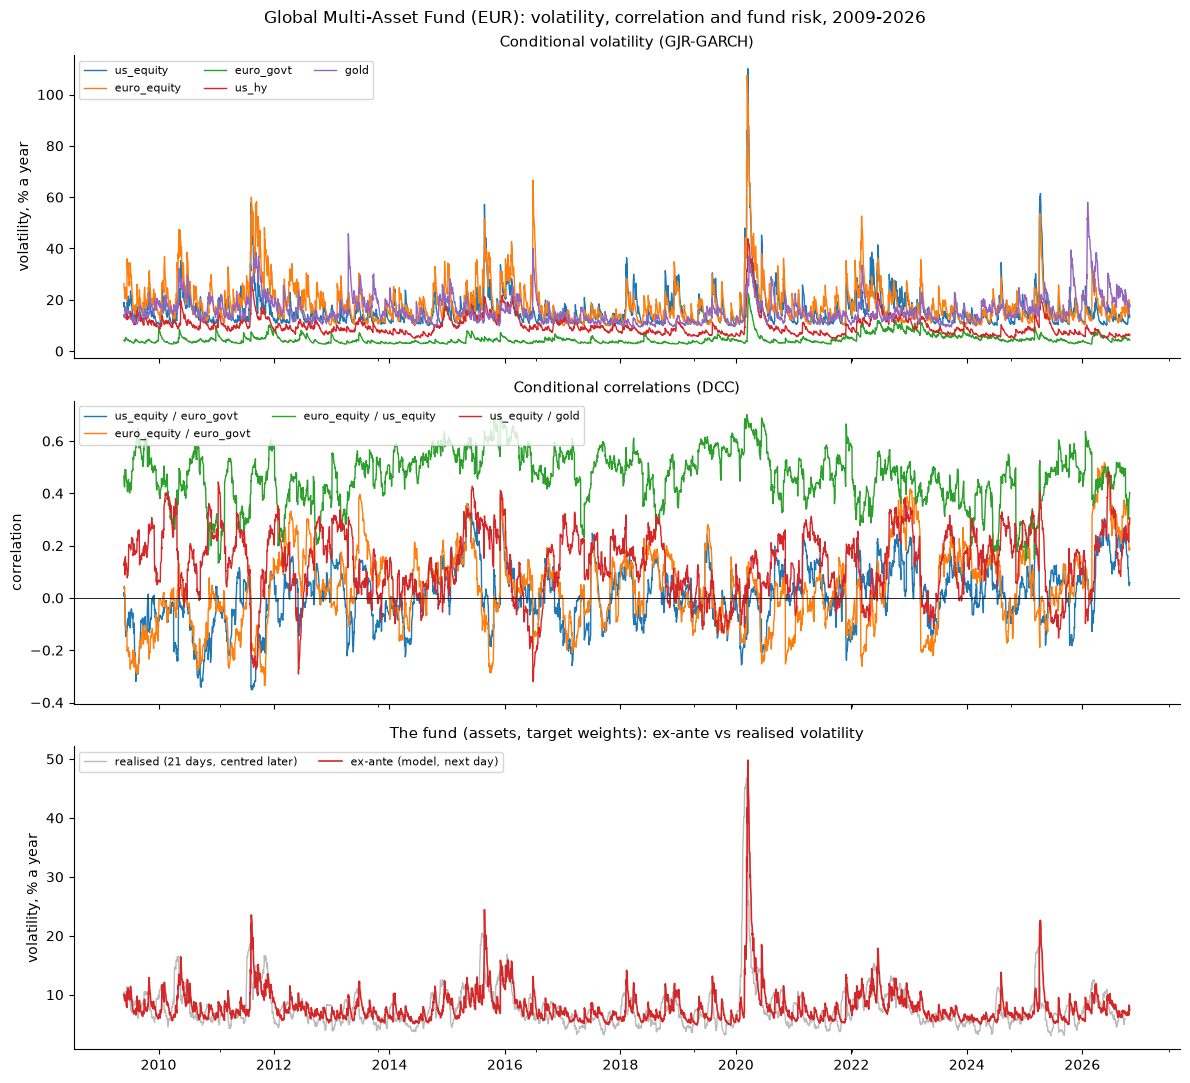

In [16]:
# 3.3 Tomorrow's covariance (Equation 8), the fund's ex-ante volatility tonight, and the risk-history chart
sig_next = gjr_par["sigma_next"].to_numpy()                     # % per day
Sigma = np.outer(sig_next, sig_next) * R_next                   # D R D
print(f"Sigma symmetric: {np.allclose(Sigma, Sigma.T)}, positive definite: {np.linalg.eigvalsh(Sigma).min() > 0}, "
      f"diagonal = sigma_next^2: {np.allclose(np.diag(Sigma), sig_next ** 2)}")

# tonight's positions: the drifted weights (the last day is not a month-end in reality)
w_tonight = hedged["w_drift"].iloc[-1]
w_tonight = w_tonight / w_tonight.sum()
vol_p = np.sqrt(w_tonight.to_numpy() @ Sigma @ w_tonight.to_numpy())
lim = cfg["limits"]["volatility_annual"]
print(f"\nFund (assets only) ex-ante volatility tonight: {vol_p:.3f}% a day = {np.sqrt(252) * vol_p:.2f}% a year "
      f"(limit {100 * lim:.0f}%: utilisation {np.sqrt(252) * vol_p / (100 * lim):.0%})")
contrib = w_tonight.to_numpy() * (Sigma @ w_tonight.to_numpy()) / vol_p ** 2
print("Share of variance by asset (Euler, Equation 18):")
print(pd.Series(contrib, index=names).round(3).sort_values(ascending=False).to_string())
print(f"Sum of shares: {contrib.sum():.4f}")

# history: ex-ante vol with target weights, in-sample sigma_t and R_t, vs realised 21-day vol
w = target.to_numpy()
cov_t = SIG.to_numpy()[:, :, None] * SIG.to_numpy()[:, None, :] * R_t      # D_t R_t D_t for every day
exante = np.sqrt(252) * np.sqrt(np.einsum("i,tij,j->t", w, cov_t, w))
fund_assets_ret = 100 * (rets @ target)                                     # fund return with target weights, %
realised = np.sqrt(252) * fund_assets_ret.rolling(21).std().shift(-20)      # vol of the next 21 days
fund_vol = pd.DataFrame({"ex-ante": exante, "realised": realised}, index=rets.index)
print(f"\nCorrelation of ex-ante with next-21-day realised vol: {fund_vol.corr().iloc[0, 1]:.2f}; "
      f"ex-ante range {fund_vol['ex-ante'].min():.1f}% to {fund_vol['ex-ante'].max():.1f}% "
      f"(max on {fund_vol['ex-ante'].idxmax().date()})")

vol_ann = np.sqrt(252) * SIG[["us_equity", "euro_equity", "euro_govt", "us_hy", "gold"]]
corr = pd.DataFrame({f"{i} / {j}": R_t[:, names.index(i), names.index(j)]
                     for i, j in [("us_equity", "euro_govt"), ("euro_equity", "euro_govt"),
                                  ("euro_equity", "us_equity"), ("us_equity", "gold")]}, index=rets.index)
fig = plot_risk_history(vol_ann, corr, fund_vol, "Global Multi-Asset Fund (EUR): volatility, correlation and fund risk, 2009-2026")
fig.savefig(FIGURES / "risk_history.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# 4.1 Risk factors (8 local returns + EUR/USD + VIX), check against the EUR returns, then GJR + DCC on all 10
fac = factor_returns(prices_clean, eurusd, market["vix"])
print(f"Factors: {list(fac.columns)}; {len(fac):,} days, {fac.index[0].date()} to {fac.index[-1].date()}; "
      f"missing {int(fac.isna().sum().sum())}")
print(f"Same calendar as the EUR returns: {fac.index.equals(rets.index)}")
rebuilt = eur_from_factors(fac, assets["currency"])
print(f"Equation 1 rebuilds the EUR returns exactly: {np.allclose(rebuilt.to_numpy(), rets.to_numpy())} "
      f"(max diff {np.abs(rebuilt - rets).max().max():.1e})")

# GJR on every factor (in %), then DCC on the 10 residual series
fac_pct = 100 * fac
t0 = time.time()
gjr_f, Z_f, SIG_f = fit_gjr_all(fac_pct)
dcc_f = fit_dcc(Z_f)
print(f"\nGJR (10 factors) + DCC in {time.time() - t0:.1f} s; GJR all converged {gjr_f['converged'].all()}, "
      f"DCC converged {dcc_f['converged']}: a = {dcc_f['a']:.4f}, b = {dcc_f['b']:.4f}")

tab = gjr_f[["alpha", "gamma", "beta", "persistence"]].copy()
tab["vol % (ann.)"] = np.sqrt(252) * fac_pct.std()
tab["vol tomorrow % (ann.)"] = np.sqrt(252) * gjr_f["sigma_next"]
tab["LB(20) z^2"] = [ljung_box(Z_f[c] ** 2)[0] for c in Z_f]
print(tab.round(3).to_string())

fn = list(Z_f.columns)
Rn = pd.DataFrame(dcc_f["R_next"], fn, fn)
print("\nTomorrow's correlations of EUR/USD and the VIX with the assets:")
print(Rn.loc[["eurusd", "vix"]].round(2).to_string())
avg = pd.DataFrame(dcc_f["R"].mean(axis=0), fn, fn)
print(f"\nAverage correlation: VIX / US equities {avg.loc['vix', 'us_equity']:.2f}, "
      f"EUR/USD / US equities {avg.loc['eurusd', 'us_equity']:.2f}, EUR/USD / gold {avg.loc['eurusd', 'gold']:.2f}")

fac.to_csv(OUT / "factor_returns.csv")
print("Saved data/processed/factor_returns.csv")

Factors: ['euro_equity', 'us_equity', 'em_equity', 'euro_govt', 'euro_ig', 'us_hy', 'gold', 'commodities', 'eurusd', 'vix']; 4,302 days, 2009-05-27 to 2026-10-28; missing 0
Same calendar as the EUR returns: True
Equation 1 rebuilds the EUR returns exactly: True (max diff 4.4e-16)

GJR (10 factors) + DCC in 58.2 s; GJR all converged False, DCC converged True: a = 0.0185, b = 0.9660
             alpha  gamma   beta  persistence  vol % (ann.)  vol tomorrow % (ann.)  LB(20) z^2
euro_equity  0.000  0.212  0.864        0.970        20.067                 16.420      11.673
us_equity    0.011  0.239  0.832        0.962        17.108                 12.359      13.815
em_equity    0.019  0.114  0.899        0.975        22.121                 22.627      17.073
euro_govt    0.056  0.044  0.899        0.977         5.036                  4.099      19.403
euro_ig      0.078  0.059  0.870        0.978         4.165                  2.777       8.012
us_hy        0.032  0.177  0.879        0.999 

In [18]:
# 4.2 Which factor fit failed? Refit with the robust (multi-start) estimator and cross-check with arch
failed = gjr_f.index[~gjr_f["converged"]].tolist()
print(f"Not converged in 4.1: {failed}")

t0 = time.time()
gjr_f, Z_f, SIG_f = fit_gjr_all(fac_pct)                       # robust fit (multi-start)
print(f"Refit in {time.time() - t0:.1f} s; all converged now: {gjr_f['converged'].all()}")
print(gjr_f[["alpha", "gamma", "beta", "persistence", "loglik", "converged", "message"]].to_string())

for a in failed + ["us_hy"]:
    if a in failed[:-0 or None] and a == "us_hy" and "us_hy" in failed:
        pass
for a in dict.fromkeys(failed + ["us_hy"]):                     # the failed ones, and us_hy in any case
    res = arch_model(fac_pct[a], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal",
                     rescale=False).fit(disp="off")
    p = res.params
    print(f"\n{a}: ours alpha {gjr_f.loc[a, 'alpha']:.4f} gamma {gjr_f.loc[a, 'gamma']:.4f} beta {gjr_f.loc[a, 'beta']:.4f} "
          f"persistence {gjr_f.loc[a, 'persistence']:.4f} loglik {gjr_f.loc[a, 'loglik']:.2f}")
    print(f"{' ' * len(a)}  arch alpha {p['alpha[1]']:.4f} gamma {p['gamma[1]']:.4f} beta {p['beta[1]']:.4f} "
          f"persistence {p['alpha[1]'] + p['gamma[1]'] / 2 + p['beta[1]']:.4f} loglik {res.loglikelihood:.2f}")

dcc_f = fit_dcc(Z_f)
print(f"\nDCC on the refitted residuals: a = {dcc_f['a']:.4f}, b = {dcc_f['b']:.4f}, converged {dcc_f['converged']}")

Not converged in 4.1: ['vix']
Refit in 50.1 s; all converged now: False
                    alpha     gamma      beta  persistence        loglik  converged                                         message
euro_equity  9.567116e-20  0.211884  0.863965     0.969907  -6486.044520       True            Optimization terminated successfully
us_equity    1.118791e-02  0.238842  0.831804     0.962413  -5492.943387       True            Optimization terminated successfully
em_equity    1.914676e-02  0.114105  0.899105     0.975305  -7037.558794       True            Optimization terminated successfully
euro_govt    5.566641e-02  0.043729  0.899414     0.976945   -576.643503       True            Optimization terminated successfully
euro_ig      7.800881e-02  0.058771  0.870129     0.977523    716.558996       True            Optimization terminated successfully
us_hy        3.158722e-02  0.176769  0.878979     0.998950  -1898.375139       True            Optimization terminated successfully
gold

In [19]:
# 4.3 GJR with the backcast starting variance: refit the 10 factors, match arch, refit DCC
t0 = time.time()
gjr_f, Z_f, SIG_f = fit_gjr_all(fac_pct)
print(f"Refit in {time.time() - t0:.1f} s; all converged: {gjr_f['converged'].all()}")

rows = {}
for a in ["us_hy", "vix", "us_equity", "euro_govt", "eurusd"]:
    res = arch_model(fac_pct[a], mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal",
                     rescale=False).fit(disp="off")
    p = res.params
    rows[a] = {"loglik ours": gjr_f.loc[a, "loglik"], "loglik arch": res.loglikelihood,
               "diff": gjr_f.loc[a, "loglik"] - res.loglikelihood,
               "persistence ours": gjr_f.loc[a, "persistence"],
               "persistence arch": p["alpha[1]"] + p["gamma[1]"] / 2 + p["beta[1]"],
               "gamma ours": gjr_f.loc[a, "gamma"], "gamma arch": p["gamma[1]"]}
print("\nComparison with arch:")
print(pd.DataFrame(rows).T.round(4).to_string())

tab = gjr_f[["alpha", "gamma", "beta", "persistence"]].copy()
tab["vol tomorrow % (ann.)"] = np.sqrt(252) * gjr_f["sigma_next"]
tab["LB(20) z^2"] = [ljung_box(Z_f[c] ** 2)[0] for c in Z_f]
print("\n" + tab.round(3).to_string())

dcc_f = fit_dcc(Z_f)
print(f"\nDCC: a = {dcc_f['a']:.4f}, b = {dcc_f['b']:.4f}, converged {dcc_f['converged']}")
gjr_f.to_csv(OUT / "gjr_factors_full_sample.csv")
Z_f.to_csv(OUT / "residuals_factors_full_sample.csv")
print("Saved data/processed/gjr_factors_full_sample.csv and residuals_factors_full_sample.csv")

Refit in 48.7 s; all converged: False

Comparison with arch:
           loglik ours  loglik arch    diff  persistence ours  persistence arch  gamma ours  gamma arch
us_hy       -1898.3751   -1898.3861  0.0110            0.9990            0.9990      0.1768      0.1769
vix        -14577.7120  -14577.7449  0.0329            0.8340            0.8340     -0.3099     -0.3099
us_equity   -5492.9434   -5492.9621  0.0187            0.9624            0.9624      0.2388      0.2389
euro_govt    -576.6435    -576.6402 -0.0033            0.9769            0.9769      0.0437      0.0437
eurusd      -3035.6146   -3035.6158  0.0012            0.9954            0.9954      0.0168      0.0168

             alpha  gamma   beta  persistence  vol tomorrow % (ann.)  LB(20) z^2
euro_equity  0.000  0.212  0.864        0.970                 16.420      11.673
us_equity    0.011  0.239  0.832        0.962                 12.359      13.815
em_equity    0.019  0.114  0.899        0.975                 22.627   

In [20]:
# 4.4 Tonight's FHS scenarios, the fund's scenario P&L (put revalued in full), VaR and ES
# (1) the fund as held tonight: rerun the history with the corrected month-end rule
hedged = fund_history(rets, target, cfg["fund"]["nav"], put=put_args)
today = rets.index[-1]
nav_t, A_t = hedged["nav"].iloc[-1], hedged["assets"].iloc[-1]
w_t = hedged["w_close"].iloc[-1]
print(f"Tonight ({today.date()}): NAV EUR {nav_t / 1e6:,.2f}m = assets {A_t / 1e6:,.2f}m + put "
      f"{hedged['put_value'].iloc[-1] / 1e3:,.0f}k; last roll {hedged['put_expiry'].iloc[-1] - pd.DateOffset(months=3):%Y-%m-%d}, "
      f"expiry {hedged['put_expiry'].iloc[-1].date()}, strike {hedged['put_strike'].iloc[-1]:,.1f}")
print(f"Weights are drifted (not reset): {not np.allclose(w_t, target)}")

mk = pm.loc[:today].iloc[-1]
expiry = hedged["put_expiry"].iloc[-1]
next_day = today + pd.offsets.BDay(1)
put_now = {"units": hedged["put_units"].iloc[-1], "K": hedged["put_strike"].iloc[-1],
           "T": (expiry - today).days / 365, "dt": (next_day - today).days / 365,
           "r": mk["r"], "q": ov["dividend_yield"], "S0": mk["S"], "sigma0": mk["sigma"], "X0": mk["X"],
           "value0": hedged["put_value"].iloc[-1], "index_factor": ov["underlying"]}
v_check = put_now["units"] * bs_put(mk["S"], put_now["K"], put_now["T"], mk["r"], put_now["q"], mk["sigma"]) / mk["X"]
print(f"Put value tonight reproduced by the pricer: {np.isclose(v_check, put_now['value0'])} (EUR {v_check:,.0f})")

# (2) FHS scenarios for tomorrow (in %), then decimals
mu = gjr_f["mu"].to_numpy()
scen_pct = fhs_scenarios(Z_f.to_numpy(), dcc_f["R"], gjr_f["sigma_next"].to_numpy(), dcc_f["R_next"], mu)
scen = pd.DataFrame(scen_pct / 100, index=Z_f.index, columns=Z_f.columns)
vol_s = scen_pct.std(axis=0)
print(f"\nScenario volatility / sigma_next: min {(vol_s / gjr_f['sigma_next']).min():.3f}, max {(vol_s / gjr_f['sigma_next']).max():.3f}")
corr_gap = np.abs(np.corrcoef(scen_pct.T) - dcc_f["R_next"]).max()
print(f"Largest gap between scenario correlations and R_next: {corr_gap:.3f}")

# (3) scenario P&L and risk measures
levels = cfg["measures"]["var_levels"]
pnl = scenario_pnl(scen, assets["currency"], w_t, A_t, put=put_now)
pnl0 = scenario_pnl(scen, assets["currency"], w_t, A_t, put=None)
rows = {}
for name, L in [("with put", -pnl["total"]), ("assets only", -pnl0["total"])]:
    t = var_es(L.to_numpy(), levels)
    for q in levels:
        rows[(name, q)] = {"VaR EUR k": t.loc[q, "VaR"] / 1e3, "VaR % NAV": 100 * t.loc[q, "VaR"] / nav_t,
                           "ES EUR k": t.loc[q, "ES"] / 1e3, "ES % NAV": 100 * t.loc[q, "ES"] / nav_t,
                           "n beyond": t.loc[q, "n beyond"]}
print("\nTonight's 1-day VaR and ES (FHS, 4,302 scenarios):")
print(pd.DataFrame(rows).T.round(2).to_string())

# (4) the put in the scenarios
worst = pnl["total"].nsmallest(5).index
print("\nThe 5 worst scenarios (historical day of the shock):")
print(pd.DataFrame({"assets EUR k": pnl.loc[worst, "assets"] / 1e3, "put EUR k": pnl.loc[worst, "put"] / 1e3,
                    "total EUR k": pnl.loc[worst, "total"] / 1e3, "US eq %": 100 * scen.loc[worst, "us_equity"],
                    "VIX change %": 100 * (np.exp(scen.loc[worst, "vix"]) - 1)}).round(1).to_string())
small = scen["us_equity"].abs() < 0.002
dS = mk["S"] * scen.loc[small, "us_equity"]
delta_pnl = put_now["units"] * bs_put_delta(mk["S"], put_now["K"], put_now["T"], mk["r"], put_now["q"], mk["sigma"]) * dS / mk["X"]
print(f"\nSmall index moves (|move| < 0.2%): put P&L vs delta x move, correlation {np.corrcoef(pnl.loc[small, 'put'], delta_pnl)[0, 1]:.2f}")

scen.to_csv(OUT / "fhs_scenarios_tonight.csv")
pnl.to_csv(OUT / "scenario_pnl_tonight.csv")
print("Saved data/processed/fhs_scenarios_tonight.csv and scenario_pnl_tonight.csv")

Tonight (2026-10-28): NAV EUR 329.23m = assets 329.14m + put 90k; last roll 2026-09-30, expiry 2026-12-30, strike 6,886.4
Weights are drifted (not reset): True
Put value tonight reproduced by the pricer: True (EUR 90,433)

Scenario volatility / sigma_next: min 0.983, max 1.019
Largest gap between scenario correlations and R_next: 0.021

Tonight's 1-day VaR and ES (FHS, 4,302 scenarios):
                   VaR EUR k  VaR % NAV  ES EUR k  ES % NAV  n beyond
with put    0.975    2967.84       0.90   3850.02      1.17     108.0
            0.990    3771.50       1.15   4746.53      1.44      44.0
            0.999    5983.60       1.82   6913.10      2.10       5.0
assets only 0.975    3040.06       0.92   4108.46      1.25     108.0
            0.990    4016.67       1.22   5113.76      1.55      44.0
            0.999    6315.25       1.92   7524.15      2.29       5.0

The 5 worst scenarios (historical day of the shock):
            assets EUR k  put EUR k  total EUR k  US eq %  VIX cha

In [21]:
# 4.5 Tonight's VaR / ES with four methods: HS (500 days), normal, FHS, FHS + EVT
levels = [0.975, 0.99, 0.995, 0.999]
L_fhs = -pnl["total"].to_numpy()

# (1) HS: the last 500 days' raw factor returns applied to tonight's positions (put revalued)
W = cfg["models"]["hs_window"]
hs_pnl = scenario_pnl(fac.iloc[-W:], assets["currency"], w_t, A_t, put=put_now)
L_hs = -hs_pnl["total"].to_numpy()

# (2) normal with the same mean and volatility as the FHS P&L
m, s = pnl["total"].mean(), pnl["total"].std()
z = stats.norm.ppf(levels)
normal = pd.DataFrame({"VaR": -m + s * z, "ES": -m + s * stats.norm.pdf(z) / (1 - np.array(levels))}, index=levels)
print(f"Normal check: ES 97.5% / VaR 99% = {normal.loc[0.975, 'ES'] / normal.loc[0.99, 'VaR']:.3f} (theory 1.005)")

# (3) FHS empirical and (4) FHS + EVT
fhs_t = var_es(L_fhs, levels)
evt_t, gfit = evt_var_es(L_fhs, levels, cfg["models"]["evt_tail_share"])
print(f"GPD on the worst {cfg['models']['evt_tail_share']:.0%} of FHS losses: threshold EUR {gfit['u'] / 1e3:,.0f}k, "
      f"{gfit['n']} excesses, xi = {gfit['xi']:.3f}, beta = EUR {gfit['beta'] / 1e3:,.0f}k, converged {gfit['converged']}")

rows = {}
for name, t in [("HS (500 d)", var_es(L_hs, levels)), ("Normal", normal), ("FHS", fhs_t), ("FHS + EVT", evt_t)]:
    for q in levels:
        rows[(q, name)] = {"VaR % NAV": 100 * t.loc[q, "VaR"] / nav_t, "ES % NAV": 100 * t.loc[q, "ES"] / nav_t,
                           "VaR EUR k": t.loc[q, "VaR"] / 1e3, "ES EUR k": t.loc[q, "ES"] / 1e3}
comp = pd.DataFrame(rows).T
comp.index.names = ["level", "method"]
print("\nTonight's 1-day VaR / ES by method:")
print(comp.round(2).to_string())

# (5) model spread and limit utilisation of the main measures (FHS)
v99 = comp.xs(0.99, level="level")["VaR % NAV"]
print(f"\nVaR 99% across methods: {v99.min():.2f}% to {v99.max():.2f}% of NAV (spread {v99.max() / v99.min() - 1:.0%})")
lim = cfg["limits"]
print(f"Limits (FHS): VaR 99% {comp.loc[(0.99, 'FHS'), 'VaR % NAV']:.2f}% / {100 * lim['var_99_1d']:.1f}% "
      f"= {comp.loc[(0.99, 'FHS'), 'VaR % NAV'] / (100 * lim['var_99_1d']):.0%}; "
      f"ES 97.5% {comp.loc[(0.975, 'FHS'), 'ES % NAV']:.2f}% / {100 * lim['es_975_1d']:.1f}% "
      f"= {comp.loc[(0.975, 'FHS'), 'ES % NAV'] / (100 * lim['es_975_1d']):.0%}")
comp.to_csv(OUT / "var_es_tonight.csv")
print("Saved data/processed/var_es_tonight.csv")

Normal check: ES 97.5% / VaR 99% = 1.005 (theory 1.005)
GPD on the worst 10% of FHS losses: threshold EUR 1,606k, 431 excesses, xi = 0.010, beta = EUR 934k, converged True

Tonight's 1-day VaR / ES by method:
                  VaR % NAV  ES % NAV  VaR EUR k  ES EUR k
level method                                              
0.975 HS (500 d)       0.92      1.35    3025.73   4430.20
0.990 HS (500 d)       1.22      1.76    4022.17   5797.64
0.995 HS (500 d)       1.40      2.05    4622.21   6759.31
0.999 HS (500 d)       2.35      2.51    7735.95   8252.00
0.975 Normal           0.80      0.96    2641.03   3169.39
0.990 Normal           0.96      1.10    3153.37   3627.24
0.995 Normal           1.06      1.20    3502.24   3944.30
0.999 Normal           1.28      1.40    4221.58   4608.73
0.975 FHS              0.90      1.17    2967.84   3850.02
0.990 FHS              1.15      1.44    3771.50   4746.53
0.995 FHS              1.32      1.66    4355.87   5455.30
0.999 FHS              1

In [24]:
# 5.1 Simulate 10,000 paths of 20 days for the 10 factors, with checks
dcc_f = fit_dcc(Z_f)                                            # refit to get Q_next (new output)
e_f = filtered_shocks(Z_f.to_numpy(), dcc_f["R"])
print(f"Filtered shocks: {e_f.shape}; std min {e_f.std(axis=0).min():.3f}, max {e_f.std(axis=0).max():.3f}; "
      f"largest correlation {np.abs(np.corrcoef(e_f.T) - np.eye(e_f.shape[1])).max():.3f} (should be near 0)")

g = gjr_f
args = dict(e=e_f, mu=g["mu"], omega=g["omega"], alpha=g["alpha"], gamma=g["gamma"], beta=g["beta"],
            sigma_next=g["sigma_next"], Q_next=dcc_f["Q_next"], Qbar=dcc_f["Qbar"], a=dcc_f["a"], b=dcc_f["b"],
            horizon=cfg["models"]["horizon_days"], n_paths=cfg["models"]["n_paths"], seed=cfg["models"]["seed"])
t0 = time.time()
paths = simulate_paths(**args)
print(f"\nSimulated {paths.shape} (paths, days, factors) in {time.time() - t0:.1f} s")

# (a) day 1 of the paths vs tonight's FHS scenarios: same volatility per factor
day1 = paths[:, 0, :]
print("Day-1 volatility / sigma_next:", np.round(day1.std(axis=0) / g["sigma_next"].to_numpy(), 3))
print(f"US equities 1% quantile: paths day 1 {np.quantile(day1[:, 1], 0.01):.3f}%, FHS {np.quantile(scen_pct[:, 1], 0.01):.3f}%")

# (b) volatility along the paths vs the GJR expectation: sigma2_h -> long-run at speed = persistence
for k, f_ in enumerate(names_f := list(Z_f.columns)):
    if f_ not in ("us_equity", "euro_govt", "us_hy", "vix"):
        continue
    sim_vol = paths[:, :, k].std(axis=0)
    p_ = g.loc[f_, "persistence"]; lr = g.loc[f_, "omega"] / (1 - p_)
    exp_vol = np.sqrt(lr + p_ ** np.arange(paths.shape[1]) * (g.loc[f_, "sigma_next"] ** 2 - lr))
    print(f"{f_:10s}: day 1 {sim_vol[0]:.3f} -> day 20 {sim_vol[-1]:.3f} (GJR expectation {exp_vol[0]:.3f} -> {exp_vol[-1]:.3f}; "
          f"long run {np.sqrt(lr):.3f})")

# (c) constant-volatility test: alpha = gamma = beta = 0, omega = sigma^2, no DCC dynamics -> sqrt(20) exactly
test = dict(args, alpha=0 * g["alpha"], gamma=0 * g["gamma"], beta=0 * g["beta"], omega=g["sigma_next"] ** 2,
            a=0.0, b=0.0, Q_next=dcc_f["Qbar"], n_paths=20_000)
p_const = simulate_paths(**test)
ratio = (p_const - g["mu"].to_numpy()).sum(axis=1).std(axis=0) / ((p_const[:, 0] - g["mu"].to_numpy()).std(axis=0))
print(f"\nConstant-volatility test: 20-day vol / 1-day vol = {ratio.min():.3f} to {ratio.max():.3f} (sqrt(20) = {np.sqrt(20):.3f})")

Filtered shocks: (4302, 10); std min 0.961, max 1.030; largest correlation 0.019 (should be near 0)

Simulated (10000, 20, 10) (paths, days, factors) in 1.5 s
Day-1 volatility / sigma_next: [0.994 0.979 0.998 0.991 0.968 0.979 0.987 0.989 0.997 0.993]
US equities 1% quantile: paths day 1 -2.130%, FHS -2.178%
us_equity : day 1 0.763 -> day 20 1.019 (GJR expectation 0.779 -> 0.904; long run 1.007)
euro_govt : day 1 0.256 -> day 20 0.285 (GJR expectation 0.258 -> 0.275; long run 0.303)
us_hy     : day 1 0.245 -> day 20 0.324 (GJR expectation 0.250 -> 0.316; long run 1.397)
vix       : day 1 6.842 -> day 20 8.579 (GJR expectation 6.889 -> 7.633; long run 7.657)

Constant-volatility test: 20-day vol / 1-day vol = 4.437 to 4.541 (sqrt(20) = 4.472)


In [26]:
# 5.2 UCITS absolute VaR: 99%, 20 business days, tonight's positions held, put revalued at the horizon
names_f = list(Z_f.columns)
h = cfg["models"]["horizon_days"]
fac_h = compound_paths(paths, names_f)
horizon_end = today + pd.offsets.BDay(h)
put_h = dict(put_now, dt=(horizon_end - today).days / 365)
print(f"Horizon: {h} business days, {today.date()} -> {horizon_end.date()} ({(horizon_end - today).days} calendar days); "
      f"put expiry {expiry.date()}")

pnl_h = scenario_pnl(fac_h, assets["currency"], w_t, A_t, put=put_h)
pnl_h0 = scenario_pnl(fac_h, assets["currency"], w_t, A_t, put=None)
lv = [0.95, 0.99]
t_put = var_es(-pnl_h["total"].to_numpy(), lv)
t_no = var_es(-pnl_h0["total"].to_numpy(), lv)

# the sqrt(20) shortcuts, from tonight's 1-day numbers (Step 4.5)
v1_fhs = comp.loc[(0.99, "FHS"), "VaR EUR k"] * 1e3
v1_norm = comp.loc[(0.99, "Normal"), "VaR EUR k"] * 1e3
ucits = t_put.loc[0.99, "VaR"]
lim = cfg["limits"]["ucits_var_99_20d"]
rows = {"Simulated paths, with put": ucits, "Simulated paths, assets only": t_no.loc[0.99, "VaR"],
        "sqrt(20) x FHS 1-day VaR": np.sqrt(h) * v1_fhs, "sqrt(20) x normal 1-day VaR": np.sqrt(h) * v1_norm}
tab = pd.DataFrame({"VaR 99% 20d EUR m": {k: v / 1e6 for k, v in rows.items()},
                    "% NAV": {k: 100 * v / nav_t for k, v in rows.items()},
                    "vs simulated": {k: v / ucits - 1 for k, v in rows.items()}})
print("\nUCITS absolute VaR (99%, 20 days):")
print(tab.round(3).to_string())
print(f"\nES 99% 20d with put: {100 * t_put.loc[0.99, 'ES'] / nav_t:.2f}% NAV; "
      f"utilisation of the UCITS limit ({100 * lim:.0f}%): {ucits / nav_t / lim:.0%}")
print(f"Put P&L over 20 days: mean EUR {pnl_h['put'].mean() / 1e3:,.0f}k (time decay), "
      f"in the worst 1% of paths EUR {pnl_h.loc[pnl_h['total'] <= pnl_h['total'].quantile(0.01), 'put'].mean() / 1e3:,.0f}k")

# effective persistence: alpha + gamma * E[z^2 1(z<0)] + beta with the real shocks, vs alpha + gamma/2 + beta
eff = {f_: gjr_f.loc[f_, "alpha"] + gjr_f.loc[f_, "gamma"] * np.mean(Z_f[f_] ** 2 * (Z_f[f_] < 0)) + gjr_f.loc[f_, "beta"]
       for f_ in ["us_equity", "euro_equity", "vix"]}
print("\nPersistence: symmetric formula vs with the real (skewed) shocks:")
for f_, v in eff.items():
    print(f"  {f_:12s} {gjr_f.loc[f_, 'persistence']:.4f} -> {v:.4f}  (share of variance from falls: "
          f"{np.mean(Z_f[f_] ** 2 * (Z_f[f_] < 0)) / np.mean(Z_f[f_] ** 2):.2f})")

Horizon: 20 business days, 2026-10-28 -> 2026-11-25 (28 calendar days); put expiry 2026-12-30

UCITS absolute VaR (99%, 20 days):
                              VaR 99% 20d EUR m  % NAV  vs simulated
Simulated paths, with put                15.675  4.761         0.000
Simulated paths, assets only             18.432  5.598         0.176
sqrt(20) x FHS 1-day VaR                 16.867  5.123         0.076
sqrt(20) x normal 1-day VaR              14.102  4.283        -0.100

ES 99% 20d with put: 5.93% NAV; utilisation of the UCITS limit (20%): 24%
Put P&L over 20 days: mean EUR 190k (time decay), in the worst 1% of paths EUR 4,908k

Persistence: symmetric formula vs with the real (skewed) shocks:
  us_equity    0.9624 -> 0.9798  (share of variance from falls: 0.57)
  euro_equity  0.9699 -> 0.9804  (share of variance from falls: 0.55)
  vix          0.8340 -> 0.8712  (share of variance from falls: 0.38)


In [28]:
# 6.1 Risk decomposition of tonight's VaR 99% and ES 97.5% (FHS scenarios): by position, asset class, risk factor
by_pos, by_fac = pnl_contributions(scen, assets["currency"], w_t, A_t, put=put_now)
print(f"Positions add up to the fund's P&L: {np.allclose(by_pos.sum(axis=1), pnl['total'])}; "
      f"factors add up too: {np.allclose(by_fac.sum(axis=1), pnl['total'])}")

dec = euler_decomposition(by_pos)
print(f"\nVaR 99% EUR {dec.attrs['VaR'] / 1e6:.3f}m (Step 4.4: {comp.loc[(0.99, 'FHS'), 'VaR EUR k'] / 1e3:.3f}m); "
      f"ES 97.5% EUR {dec.attrs['ES'] / 1e6:.3f}m (Step 4.4: {comp.loc[(0.975, 'FHS'), 'ES EUR k'] / 1e3:.3f}m)")
print(f"Component ES adds up to ES: {np.isclose(dec['component ES'].sum(), dec.attrs['ES'])}; "
      f"component VaR adds up to VaR: {np.isclose(dec['component VaR'].sum(), dec.attrs['VaR'])}")

nav_w = pd.concat([w_t * A_t, pd.Series({"put": put_now["value0"]})]) / nav_t
view = dec.assign(**{"weight % NAV": 100 * nav_w})
view[["component VaR", "component ES", "incremental VaR"]] /= 1e3
for c in ["share of VaR", "share of ES"]:
    view[c] = 100 * view[c]
print("\nBy position (EUR k; shares in %):")
print(view[["weight % NAV", "component VaR", "share of VaR", "component ES", "share of ES", "incremental VaR"]]
      .round(1).to_string())

# by asset class (the put is its own class)
cls = assets["asset_class"].to_dict() | {"put": "Options overlay"}
by_cls = by_pos.T.groupby(cls).sum().T
dec_cls = euler_decomposition(by_cls)
print("\nBy asset class:")
print(pd.DataFrame({"weight % NAV": 100 * nav_w.groupby(cls).sum(),
                    "share of VaR %": 100 * dec_cls["share of VaR"],
                    "share of ES %": 100 * dec_cls["share of ES"]}).round(1).to_string())

# by risk factor: local-currency moves, FX, the put
dec_fac = euler_decomposition(by_fac)
print("\nBy risk factor (share of ES %):")
print((100 * dec_fac["share of ES"]).round(1).to_string())

# check: the normal closed-form shares (assets only, Equation 18) vs the scenario shares
r_eur_scen = eur_from_factors(scen, assets["currency"])
S = np.cov(r_eur_scen.to_numpy().T)
w_ = w_t.to_numpy()
normal_share = w_ * (S @ w_) / (w_ @ S @ w_)
dec0 = euler_decomposition(by_pos.drop(columns="put"))
print("\nAssets only - share of risk: normal (Equation 18) vs FHS component ES:")
print(pd.DataFrame({"normal %": 100 * normal_share, "FHS ES %": 100 * dec0["share of ES"]},
                   index=assets.index).round(1).to_string())

lim = cfg["limits"]["max_risk_contribution"]
top = dec["share of VaR"].drop("put").idxmax()
print(f"\nLargest single contribution to VaR: {top} {100 * dec.loc[top, 'share of VaR']:.1f}% "
      f"(limit {100 * lim:.0f}%: utilisation {dec.loc[top, 'share of VaR'] / lim:.0%})")
dec.to_csv(OUT / "decomposition_tonight.csv")

Positions add up to the fund's P&L: True; factors add up too: True

VaR 99% EUR 3.771m (Step 4.4: 3.771m); ES 97.5% EUR 3.850m (Step 4.4: 3.850m)
Component ES adds up to ES: True; component VaR adds up to VaR: True

By position (EUR k; shares in %):
             weight % NAV  component VaR  share of VaR  component ES  share of ES  incremental VaR
euro_equity          14.7          931.0          24.7         992.3         25.8            899.4
us_equity            20.4         1331.4          35.3        1331.2         34.6           1184.6
em_equity             9.6         1076.2          28.5        1052.8         27.3            987.6
euro_govt            25.0          159.6           4.2         172.9          4.5            185.5
euro_ig              12.5           64.8           1.7          89.7          2.3            190.3
us_hy                 5.1           79.7           2.1          93.1          2.4            111.5
gold                  7.4          366.0           9.7   

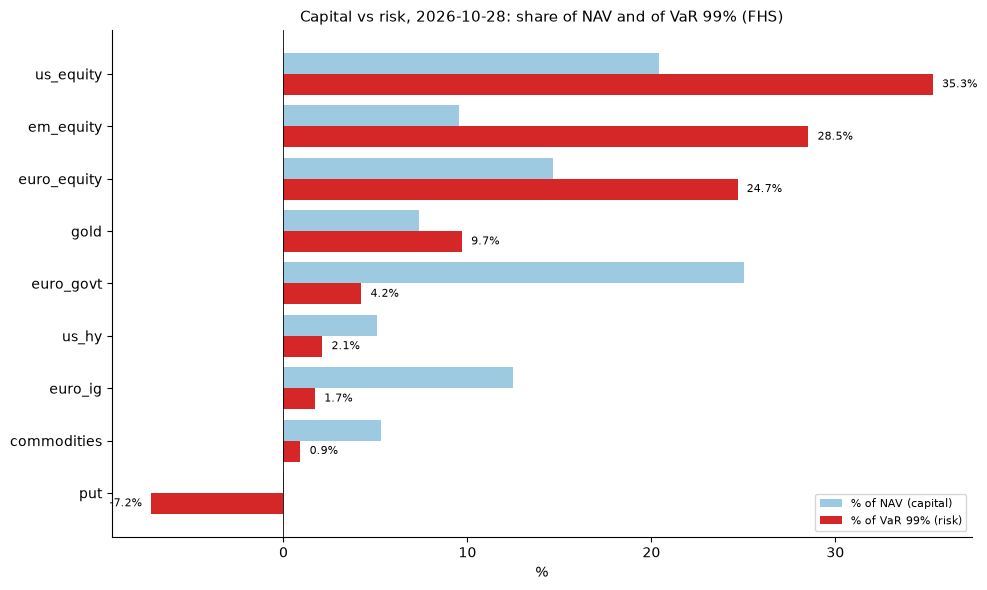

Marginal VaR (EUR of VaR per EUR 100 invested): {'euro_equity': 1.93, 'us_equity': 1.979, 'em_equity': 3.419, 'euro_govt': 0.194, 'euro_ig': 0.157, 'us_hy': 0.474, 'gold': 1.507, 'commodities': 0.199}

First 0.5% step: exact VaR change EUR -2.8k vs marginal estimate EUR -29.4k; weights sum to 1.000000

What-if (target: US share of VaR below 32%):
 moved % NAV  US equity % NAV  VaR 99% EUR k  VaR change EUR k  US share of VaR %
         0.5            19.94        3768.67             -2.82              34.05
         1.0            19.44        3732.94            -38.55              33.54
         1.5            18.94        3691.81            -79.69              32.92
         2.0            18.44        3659.10           -112.40              32.47
         2.5            17.94        3609.24           -162.25              31.80


In [30]:
# 6.2 Risk budget chart, and a what-if: move US equities into euro govt until the concentration is green
fig = plot_risk_budget(100 * nav_w, 100 * dec["share of VaR"],
                       f"Capital vs risk, {today.date()}: share of NAV and of VaR 99% (FHS)")
fig.savefig(FIGURES / "risk_budget.png", dpi=150, bbox_inches="tight")
plt.show()

def var_and_share(weights, asset="us_equity"):
    """Exact VaR 99% (EUR) and the asset's share of VaR for given asset weights (put unchanged)."""
    bp, _ = pnl_contributions(scen, assets["currency"], weights, A_t, put=put_now)
    d = euler_decomposition(bp)
    return d.attrs["VaR"], d.loc[asset, "share of VaR"]

# marginal VaR: EUR of VaR per EUR invested (component VaR / exposure)
expo = w_t * A_t
mvar = dec["component VaR"].drop("put") / expo
print("Marginal VaR (EUR of VaR per EUR 100 invested):", (100 * mvar).round(3).to_dict())

step = 0.005 * nav_t / A_t                                       # 0.5% of NAV, as a share of the assets
warn = cfg["limits"]["warning_level"] * cfg["limits"]["max_risk_contribution"]
w_new = w_t.copy()
rows = []
for k in range(1, 21):
    w_new = w_new.copy()
    w_new["us_equity"] -= step
    w_new["euro_govt"] += step
    v, sh = var_and_share(w_new)
    rows.append({"moved % NAV": 0.5 * k, "US equity % NAV": 100 * w_new["us_equity"] * A_t / nav_t,
                 "VaR 99% EUR k": v / 1e3, "VaR change EUR k": (v - dec.attrs["VaR"]) / 1e3,
                 "US share of VaR %": 100 * sh})
    if k == 1:
        approx = (mvar["euro_govt"] - mvar["us_equity"]) * step * A_t
        print(f"\nFirst 0.5% step: exact VaR change EUR {(v - dec.attrs['VaR']) / 1e3:,.1f}k vs marginal estimate "
              f"EUR {approx / 1e3:,.1f}k; weights sum to {w_new.sum():.6f}")
    if sh < warn:
        break
print(f"\nWhat-if (target: US share of VaR below {100 * warn:.0f}%):")
print(pd.DataFrame(rows).round(2).to_string(index=False))

In [32]:
# 7.1 Historical stress tests: the cumulative moves of four crises applied to tonight's fund (instantaneous shock)
cfg = load_config(CONFIG)
st = cfg["stress"]
proxy_tickers = sorted({p["ticker"] for p in st["proxies"].values()})
proxy_px = load_yahoo(proxy_tickers, start=cfg["fund"]["start"])
proxy_px.to_csv(RAW / "proxy_prices.csv")
print(f"Proxies downloaded: {history_summary(proxy_px)[['first', 'last', 'prices']].to_dict('index')}")

put_inst = dict(put_now, dt=0.0)                                # instantaneous: no time decay
rows, by_pos_st, moves_all = {}, {}, {}
for key, sc in st["historical"].items():
    mv, used = window_factor_moves(prices_clean, proxy_px, st["proxies"], eurusd, market["vix"], sc["start"], sc["end"])
    moves_all[key] = mv
    f1 = mv.to_frame().T                                          # one scenario, factor format
    bp, _ = pnl_contributions(f1, assets["currency"], w_t, A_t, put=put_inst)
    by_pos_st[key] = bp.iloc[0]
    tot = bp.iloc[0].sum()
    rows[sc["label"]] = {"P&L EUR m": tot / 1e6, "P&L % NAV": 100 * tot / nav_t,
                         "of which put EUR m": bp.iloc[0]["put"] / 1e6,
                         "US eq %": 100 * mv["us_equity"], "euro govt %": 100 * mv["euro_govt"],
                         "EUR/USD %": 100 * mv["eurusd"], "VIX end": 100 * put_now["sigma0"] * np.exp(mv["vix"]),
                         "proxies": ", ".join(f"{a}<-{t}" for a, t in used.items()) or "-"}
stress_hist = pd.DataFrame(rows).T
print("\nHistorical stress tests (instantaneous, tonight's positions):")
print(stress_hist.to_string(float_format=lambda v: f"{v:,.2f}"))

print("\nFactor moves in each window (%; VIX = log change):")
print((100 * pd.DataFrame(moves_all)).round(2).to_string())
print("\nP&L by position (EUR k):")
print((pd.DataFrame(by_pos_st) / 1e3).round(0).to_string())

# hand check of one scenario: Covid, US equities position
mv = moves_all["covid_2020"]
hand = A_t * w_t["us_equity"] * ((1 + mv["us_equity"]) / (1 + mv["eurusd"]) - 1)
print(f"\nHand check, Covid, US equities: EUR {hand / 1e3:,.0f}k vs table EUR {by_pos_st['covid_2020']['us_equity'] / 1e3:,.0f}k")
worst = stress_hist["P&L % NAV"].astype(float).min()
print(f"Worst historical stress: {worst:.2f}% of NAV (limit -{100 * cfg['limits']['worst_stress_loss']:.0f}%: "
      f"utilisation {abs(worst) / (100 * cfg['limits']['worst_stress_loss']):.0%})")

Proxies downloaded: {'IEF': {'first': datetime.date(2005, 1, 3), 'last': datetime.date(2026, 10, 28), 'prices': 5490}, 'LQD': {'first': datetime.date(2005, 1, 3), 'last': datetime.date(2026, 10, 28), 'prices': 5490}}

Historical stress tests (instantaneous, tonight's positions):
                                        P&L EUR m P&L % NAV of which put EUR m US eq % euro govt % EUR/USD % VIX end                       proxies
Lehman collapse (Sep-Oct 2008)             -34.75    -10.56              13.05  -29.08       -2.25     -3.36   49.87  euro_govt<-IEF, euro_ig<-LQD
Euro crisis and US downgrade (Aug 2011)    -15.99     -4.86               3.73  -13.50        4.00      0.73   31.53                             -
Covid crash (Feb-Mar 2020)                 -46.35    -14.08              16.20  -33.40       -1.89     -0.51   72.22                             -
Inflation and rates shock (2022)           -24.74     -7.51              10.50  -24.06      -18.17    -14.37   33.90                

In [34]:
# 7.2 Hypothetical stress tests (factor shocks), and the full stress table with and without the put
rows, by_pos_h = {}, {}
for key, sh in st["hypothetical"].items():
    mv = hypothetical_moves(sh, assets, put_now["sigma0"])
    bp, _ = pnl_contributions(mv.to_frame().T, assets["currency"], w_t, A_t, put=put_inst)
    by_pos_h[key] = bp.iloc[0]
    tot = bp.iloc[0].sum()
    rows[sh["label"]] = {"P&L EUR m": tot / 1e6, "P&L % NAV": 100 * tot / nav_t,
                         "without put % NAV": 100 * (tot - bp.iloc[0]["put"]) / nav_t,
                         "of which put EUR m": bp.iloc[0]["put"] / 1e6}
stress_hyp = pd.DataFrame(rows).T
print("Hypothetical stress tests (instantaneous, tonight's positions):")
print(stress_hyp.round(2).to_string())
print("\nP&L by position (EUR k):")
print((pd.DataFrame(by_pos_h) / 1e3).round(0).to_string())

# hand checks
govt = A_t * w_t["euro_govt"]
print(f"\nHand check, rates +100 bp, euro govt: {-7.3 * 0.01 + 0.5 * 70 * 0.01 ** 2:.4%} x EUR {govt / 1e6:.2f}m = "
      f"EUR {govt * (-0.073 + 0.0035) / 1e3:,.0f}k vs table EUR {by_pos_h['rates_plus_100bp']['euro_govt'] / 1e3:,.0f}k")
usd = A_t * w_t[assets["currency"] == "USD"].sum()
print(f"Hand check, EUR/USD +10%: USD assets EUR {usd / 1e6:.1f}m x {1 / 1.1 - 1:.2%} = EUR {usd * (1 / 1.1 - 1) / 1e6:.2f}m; "
      f"EUR/USD -10%: x {1 / 0.9 - 1:+.2%} = EUR {usd * (1 / 0.9 - 1) / 1e6:+.2f}m")

# the full stress table (historical + hypothetical), sorted by loss
hist = stress_hist[["P&L EUR m", "P&L % NAV", "of which put EUR m"]].astype(float).copy()
hist["without put % NAV"] = hist["P&L % NAV"] - 100 * hist["of which put EUR m"] * 1e6 / nav_t
all_stress = pd.concat({"historical": hist, "hypothetical": stress_hyp}).sort_values("P&L % NAV")
print("\nAll stress tests, sorted by loss:")
print(all_stress[["P&L % NAV", "without put % NAV", "P&L EUR m", "of which put EUR m"]].round(2).to_string())
all_stress.to_csv(OUT / "stress_tonight.csv")
print("Saved data/processed/stress_tonight.csv")

Hypothetical stress tests (instantaneous, tonight's positions):
                                                                           P&L EUR m  P&L % NAV  without put % NAV  of which put EUR m
Equities -20%, VIX 45                                                         -21.75      -6.61              -8.93                7.65
Rates +100 bp                                                                  -8.05      -2.45              -2.45                0.00
Credit spreads +150 bp                                                         -3.59      -1.09              -1.09                0.00
EUR/USD +10% (USD assets lose in EUR)                                         -14.31      -4.35              -4.34               -0.01
EUR/USD -10%                                                                   17.49       5.31               5.31                0.01
Combined: equities -15%, rates +100 bp, spreads +100 bp, commodities +15%     -25.22      -7.66              -9.08            

In [36]:
# 8.1 The out-of-sample engine on a short stretch: output, timing, and the look-ahead test
W = cfg["models"]["fit_window"]
eng_args = dict(currencies=assets["currency"], pm=pm, put_cfg=ov, window=W, refit_every=20,
                hs_window=cfg["models"]["hs_window"], levels=(0.975, 0.99, 0.999))
t0 = time.time()
test_out, test_par = rolling_risk(fac, hist=hedged, start=W, end=W + 100, **eng_args)
dt_ = time.time() - t0
print(f"100 days ({test_out.index[0].date()} to {test_out.index[-1].date()}) in {dt_:.0f} s "
      f"-> full run of {len(fac) - W:,} days about {dt_ * (len(fac) - W) / 100 / 60:.0f} minutes")
print(f"Missing values: {int(test_out.isna().sum().sum())}; re-estimations: {len(test_par)}, "
      f"all converged: {test_par['all converged'].all()}")
print("\nFirst 3 days, VaR 99% and ES 97.5% by method (EUR k), and the realised loss:")
show = pd.DataFrame({m: test_out[(m, "VaR", 0.99)] for m in METHODS}) / 1e3
show["ES 97.5% FHS"] = test_out[("FHS", "ES", 0.975)] / 1e3
show["realised loss"] = test_out[("loss", "", "")] / 1e3
print(show.head(3).round(0).to_string())

# look-ahead: multiply every factor return after day W + 50 by 5 -> forecasts up to that day must not change
cut = W + 50
fac_x = fac.copy()
fac_x.iloc[cut:] *= 5
rets_x = eur_from_factors(fac_x, assets["currency"])
hist_x = fund_history(rets_x, target, cfg["fund"]["nav"], put=put_args)
out_x, _ = rolling_risk(fac_x, hist=hist_x, start=W, end=W + 100, **eng_args)
cols = [c for c in test_out.columns if c[0] != "loss"]
d_cut = fac.index[cut]
print(f"\nLook-ahead test: forecasts up to and including {d_cut.date()} unchanged: "
      f"{np.allclose(test_out.loc[:d_cut, cols].values, out_x.loc[:d_cut, cols].values)}; "
      f"forecasts after it changed: {not np.allclose(test_out.loc[d_cut:, cols].iloc[1:].values, out_x.loc[d_cut:, cols].iloc[1:].values)}")

100 days (2013-06-10 to 2013-10-30) in 54 s -> full run of 3,302 days about 30 minutes
Missing values: 0; re-estimations: 5, all converged: True

First 3 days, VaR 99% and ES 97.5% by method (EUR k), and the realised loss:
                HS  Normal     FHS  FHS + EVT  ES 97.5% FHS  realised loss
date                                                                      
2013-06-10  1849.0  1474.0  1519.0     1585.0        1565.0          256.0
2013-06-11  1836.0  1421.0  1460.0     1526.0        1508.0         1254.0
2013-06-12  1757.0  1495.0  1553.0     1591.0        1575.0          546.0

Look-ahead test: forecasts up to and including 2013-08-20 unchanged: True; forecasts after it changed: True


In [37]:
# 8.2 Check that the faster GJR gives the same forecasts, then the full out-of-sample run (computed once, saved)
t0 = time.time()
chk, _ = rolling_risk(fac, hist=hedged, start=W, end=W + 100, **eng_args)
dt_ = time.time() - t0
print(f"Same forecasts as Step 8.1: {np.allclose(chk.values, test_out.values)}; "
      f"100 days now in {dt_:.0f} s -> full run about {dt_ * (len(fac) - W) / 100 / 60:.0f} minutes")

oos_file, par_file = OUT / "oos_rolling.pkl", OUT / "oos_rolling_params.pkl"
if oos_file.exists():
    oos = pd.read_pickle(oos_file); oos_par = pd.read_pickle(par_file)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    oos, oos_par = rolling_risk(fac, hist=hedged, **eng_args)
    oos.to_pickle(oos_file); oos_par.to_pickle(par_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

loss = oos[("loss", "", "")]
print(f"\n{len(oos):,} forecast days, {oos.index[0].date()} to {oos.index[-1].date()}; missing {int(oos.isna().sum().sum())}; "
      f"{len(oos_par)} re-estimations, all converged: {oos_par['all converged'].all()}")
print(f"DCC across windows: a {oos_par['a'].min():.3f}-{oos_par['a'].max():.3f}, b {oos_par['b'].min():.3f}-{oos_par['b'].max():.3f}")

# first look: breaches of VaR by method and level vs expected
rows = {}
for m in METHODS:
    rows[m] = {f"breaches {q}": int((loss > oos[(m, "VaR", q)]).sum()) for q in (0.975, 0.99, 0.999)}
first = pd.DataFrame(rows).T.astype(float)
first.loc["expected"] = [round((1 - q) * len(oos), 1) for q in (0.975, 0.99, 0.999)]
print("\nFirst look - VaR breaches (realised loss > VaR forecast the evening before):")
print(first.to_string())
print(f"\nAverage VaR 99% (% of NAV): " + ", ".join(
    f"{m} {100 * (oos[(m, 'VaR', 0.99)] / hedged['nav'].shift(1).reindex(oos.index)).mean():.2f}%" for m in METHODS))

Same forecasts as Step 8.1: True; 100 days now in 24 s -> full run about 13 minutes
Computed in 11.3 minutes and saved

3,302 forecast days, 2013-06-10 to 2026-10-28; missing 0; 166 re-estimations, all converged: True
DCC across windows: a 0.009-0.030, b 0.884-0.977

First look - VaR breaches (realised loss > VaR forecast the evening before):
           breaches 0.975  breaches 0.99  breaches 0.999
HS                  108.0           52.0            14.0
Normal               99.0           54.0            18.0
FHS                  81.0           39.0             9.0
FHS + EVT            76.0           33.0             9.0
expected             82.6           33.0             3.3

Average VaR 99% (% of NAV): HS 1.32%, Normal 1.04%, FHS 1.16%, FHS + EVT 1.20%


In [40]:
# 8.3 Formal backtests of the four methods, and the Basel traffic light
levels = (0.975, 0.99, 0.999)
T_oos = len(oos)
z2_crit = {}
for q in levels:
    c, m_ = z2_critical(T_oos, 1 - q, n_sim=2000, seed=int(1000 * q))
    z2_crit[q] = c
    print(f"Z2 at {q}: 5% critical value {c:.3f} (mean of simulated Z2 {m_:+.4f})")

bt = backtest_table(loss, oos, METHODS, levels, z2_crit)
bt.to_csv(OUT / "backtest_rolling.csv")
for q in levels:
    print(f"\n=== {q:.1%} VaR, ES at the same level (expected breaches {(1 - q) * T_oos:.1f}) ===")
    print(bt.loc[q].drop(columns=["expected", "Z2 crit"]).to_string(float_format=lambda v: f"{v:.3f}"))

# Basel traffic light: rolling 250-day 99% breaches of the main model (FHS + EVT)
main = "FHS + EVT"
tl = traffic_light((loss > oos[(main, "VaR", 0.99)]).values)
tl.index = oos.index
zones = tl["zone"].dropna().value_counts(normalize=True).reindex(["green", "yellow", "red"]).fillna(0)
print(f"\nTraffic light ({main}, 250-day windows): " + ", ".join(f"{z} {100 * v:.1f}%" for z, v in zones.items()))
worst = tl["breaches"].idxmax()
print(f"Worst window ends {worst.date()}: {int(tl['breaches'].max())} breaches")
last = (loss.iloc[-250:] > oos[(main, "VaR", 0.99)].iloc[-250:])
print(f"Tonight: {int(tl['breaches'].iloc[-1])} breaches in the last 250 days -> {tl['zone'].iloc[-1]} "
      f"(hand count {int(last.sum())}; dates: {[d.date() for d in last.index[last]]})")

# the 99.9% breaches of FHS + EVT: when, and how big
br = oos.index[loss > oos[(main, "VaR", 0.999)]]
nav_prev = hedged["nav"].shift(1).reindex(oos.index)
print(f"\n{main} 99.9% breaches ({len(br)}):")
print(pd.DataFrame({"loss % NAV": 100 * loss[br] / nav_prev[br],
                    "VaR 99.9% % NAV": 100 * oos.loc[br, (main, "VaR", 0.999)] / nav_prev[br],
                    "loss / VaR": loss[br] / oos.loc[br, (main, "VaR", 0.999)]}).round(2).to_string())

Z2 at 0.975: 5% critical value -0.181 (mean of simulated Z2 -0.0018)
Z2 at 0.99: 5% critical value -0.302 (mean of simulated Z2 -0.0019)
Z2 at 0.999: 5% critical value -1.013 (mean of simulated Z2 +0.0003)

=== 97.5% VaR, ES at the same level (expected breaches 82.6) ===
           breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p     Z2  pass all
method                                                                                          
HS              108  1.308     0.007       0.007           24             0.000 -0.446     False
Normal           99  1.199     0.075       0.081            7             0.024 -0.357     False
FHS              81  0.981     0.862       0.921            7             0.016 -0.017     False
FHS + EVT        76  0.921     0.459       0.506            6             0.026  0.030     False

=== 99.0% VaR, ES at the same level (expected breaches 33.0) ===
           breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p 

In [41]:
# 8.4 The expanding pool of filtered shocks: rerun (once, saved), then compare with the rolling pool
exp_file, exp_par_file = OUT / "oos_expanding.pkl", OUT / "oos_expanding_params.pkl"
if exp_file.exists():
    oos_x = pd.read_pickle(exp_file)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    oos_x, oos_x_par = rolling_risk(fac, hist=hedged, pool="expanding", **eng_args)
    oos_x.to_pickle(exp_file); oos_x_par.to_pickle(exp_par_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")
cols = [c for c in oos.columns if c[0] != "loss"]
print(f"First forecast identical to the rolling pool: {np.allclose(oos_x.iloc[0][cols].values, oos.iloc[0][cols].values)}")

# both versions in one table: rename the expanding methods
ren = {m: f"{m} (exp.)" for m in ["FHS", "FHS + EVT"]}
both = pd.concat([oos[[c for c in oos.columns if c[0] in ("loss", "FHS", "FHS + EVT")]],
                  oos_x[[c for c in oos_x.columns if c[0] in ("FHS", "FHS + EVT")]].rename(columns=ren, level=0)], axis=1)
methods2 = ["FHS", "FHS + EVT", "FHS (exp.)", "FHS + EVT (exp.)"]
bt2 = backtest_table(loss, both, methods2, levels, z2_crit)
bt2.to_csv(OUT / "backtest_rolling_vs_expanding.csv")
for q in levels:
    print(f"\n=== {q:.1%} (expected {(1 - q) * T_oos:.1f}) ===")
    print(bt2.loc[q].drop(columns=["expected", "Z2 crit"]).to_string(float_format=lambda v: f"{v:.3f}"))

# the cost: average VaR and ES in % of NAV
nav_prev = hedged["nav"].shift(1).reindex(oos.index)
cost = pd.DataFrame({m: {f"VaR {q}": 100 * (both[(m, 'VaR', q)] / nav_prev).mean() for q in levels}
                     for m in methods2}).T
cost["ES 0.975"] = [100 * (both[(m, "ES", 0.975)] / nav_prev).mean() for m in methods2]
print("\nAverage forecast, % of NAV (the cost of a safer model):")
print(cost.round(3).to_string())

# traffic light of the expanding FHS + EVT
tl_x = traffic_light((loss > oos_x[("FHS + EVT", "VaR", 0.99)]).values)
z_x = tl_x["zone"].dropna().value_counts(normalize=True).reindex(["green", "yellow", "red"]).fillna(0)
print("\nTraffic light, FHS + EVT (exp.): " + ", ".join(f"{z} {100 * v:.1f}%" for z, v in z_x.items()) +
      f"; tonight {int(tl_x['breaches'].iloc[-1])} breaches -> {tl_x['zone'].iloc[-1]}")

Computed in 6.2 minutes and saved
First forecast identical to the rolling pool: True

=== 97.5% (expected 82.6) ===
                  breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p     Z2  pass all
method                                                                                                 
FHS                     81  0.981     0.862       0.921            7             0.016 -0.017     False
FHS + EVT               76  0.921     0.459       0.506            6             0.026  0.030     False
FHS (exp.)              78  0.945     0.609       0.662            6             0.037 -0.004     False
FHS + EVT (exp.)        76  0.921     0.459       0.506            6             0.026  0.025     False

=== 99.0% (expected 33.0) ===
                  breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p     Z2  pass all
method                                                                                                 
FHS                  

Largest loss / VaR 99.9% ratios: [1.53, 1.31, 1.28, 1.26, 1.23, 1.16]
Model-risk multiplier for 99.9%: k = 1.23 -> 4 breaches (expected 3.3), Kupiec p 0.710, Christoffersen p 0.929
Average VaR 99.9%: 1.87% -> with add-on 2.30% of NAV
Tonight: VaR 99.9% 2.05% -> with add-on 2.52% of NAV (calibrated in-sample: to be re-checked as data arrive)


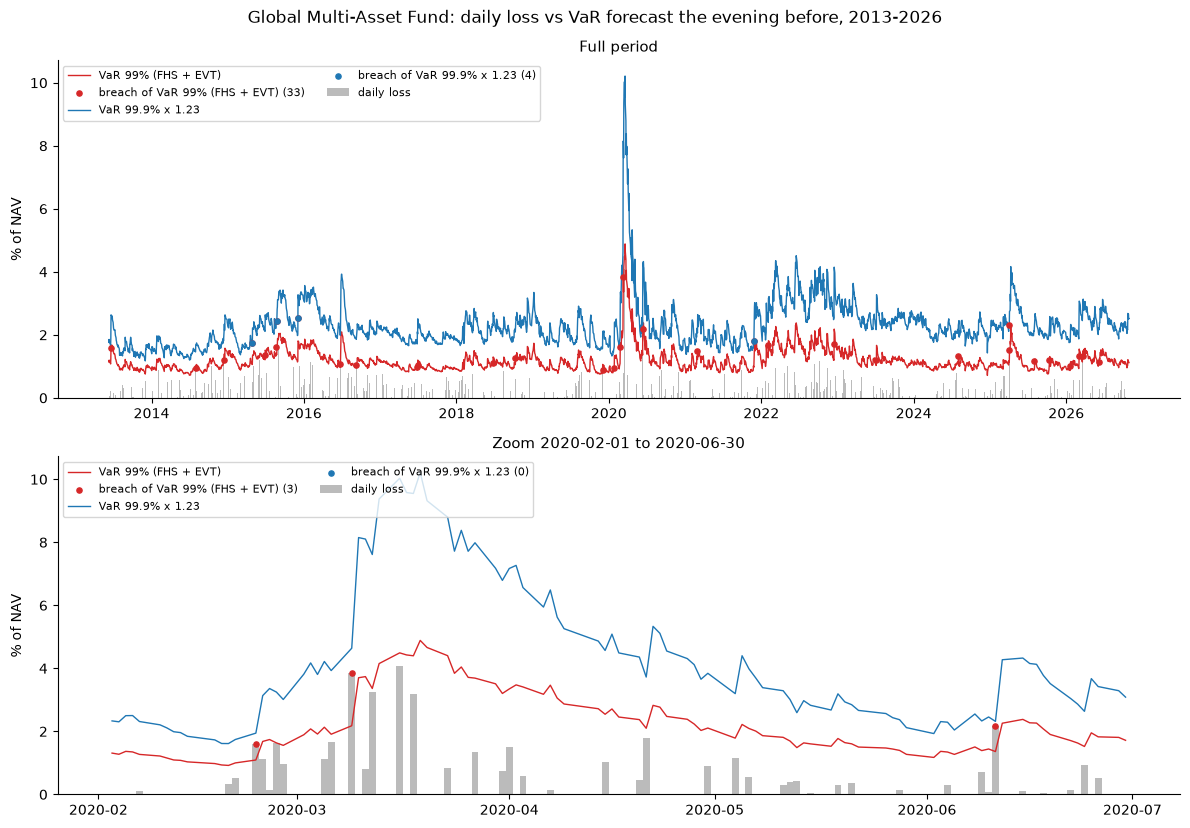

Saved data/processed/model_decision.json: {'main_model': 'FHS + EVT', 'pool': 'rolling', 'var999_multiplier': 1.23, 'calibrated_on': '2013-06-10 to 2026-10-28'}


In [43]:
# 8.5 Official model, a model-risk add-on for 99.9%, and the backtest chart
main = "FHS + EVT"                                             # rolling pool (Step 8.4: the expanding pool adds nothing)
v999 = oos[(main, "VaR", 0.999)]
ratio = (loss / v999).sort_values(ascending=False)
target_n = int(np.ceil((1 - 0.999) * T_oos))                   # 3.3 -> at most 4 breaches
k = float(np.ceil(100 * ratio.iloc[target_n]) / 100)           # smallest multiplier (2 decimals) leaving <= 4 breaches
scaled = k * v999
hits = (loss > scaled).values
from riskreport.backtest import kupiec_test, christoffersen_test
n_b, p_k = kupiec_test(hits, 0.001)
_, p_c = christoffersen_test(hits, 0.001)
print(f"Largest loss / VaR 99.9% ratios: {ratio.head(6).round(2).to_list()}")
print(f"Model-risk multiplier for 99.9%: k = {k:.2f} -> {n_b} breaches (expected {(0.001 * T_oos):.1f}), "
      f"Kupiec p {p_k:.3f}, Christoffersen p {p_c:.3f}")
print(f"Average VaR 99.9%: {100 * (v999 / nav_prev).mean():.2f}% -> with add-on {100 * (scaled / nav_prev).mean():.2f}% of NAV")
print(f"Tonight: VaR 99.9% {100 * v999.iloc[-1] / nav_prev.iloc[-1]:.2f}% -> with add-on {100 * scaled.iloc[-1] / nav_prev.iloc[-1]:.2f}% of NAV "
      "(calibrated in-sample: to be re-checked as data arrive)")

# the backtest chart: daily loss vs VaR 99% and VaR 99.9% (with add-on), % of NAV
loss_pct = 100 * loss / nav_prev
lines = {"VaR 99% (FHS + EVT)": 100 * oos[(main, "VaR", 0.99)] / nav_prev,
         f"VaR 99.9% x {k:.2f}": 100 * scaled / nav_prev}
fig = plot_var_backtest(loss_pct, lines, zoom=("2020-02-01", "2020-06-30"),
                        title="Global Multi-Asset Fund: daily loss vs VaR forecast the evening before, 2013-2026")
fig.savefig(FIGURES / "var_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

decision = {"main_model": main, "pool": "rolling", "var999_multiplier": k, "calibrated_on": f"{oos.index[0].date()} to {oos.index[-1].date()}"}
pd.Series(decision).to_json(OUT / "model_decision.json")
print(f"Saved data/processed/model_decision.json: {decision}")

In [45]:
# 9.1 Tonight and yesterday evening with the backtested model; check against the engine; change attribution
t0 = time.time()
night = evening_risk(fac, assets["currency"], hedged, len(fac) - 1, cfg, pm=pm, put_cfg=ov)
eve = evening_risk(fac, assets["currency"], hedged, len(fac) - 2, cfg, pm=pm, put_cfg=ov, prev=night["models"])
print(f"Two evenings computed in {time.time() - t0:.1f} s; models converged: {night['models']['converged']}, {eve['models']['converged']}")

nav_n, nav_e = night["nav"], eve["nav"]
tab = (100 * night["table"] / nav_n).round(3)
tab.columns = ["VaR % NAV", "ES % NAV"]
print(f"\nTonight ({night['date'].date()}), NAV EUR {nav_n / 1e6:,.2f}m - VaR / ES by method:")
print(tab.unstack("level").to_string())

# check 1: yesterday evening's forecast vs the engine's last forecast (same day, refits at different dates)
v_eng = oos[("FHS + EVT", "VaR", 0.99)].iloc[-1]
v_eve = eve["table"].loc[("FHS + EVT", 0.99), "VaR"]
print(f"\nForecast for {oos.index[-1].date()}: engine (refit every 20 days) EUR {v_eng / 1e3:,.0f}k, "
      f"evening_risk (refit on the latest window) EUR {v_eve / 1e3:,.0f}k ({v_eve / v_eng - 1:+.1%})")

# check 2 and attribution (Equation 24): position effect + market effect = change
lv = [0.99]
v_nn = var_of_positions(night["scen"], assets["currency"], night["positions"], lv).loc[0.99, "VaR"]
v_ne = var_of_positions(night["scen"], assets["currency"], eve["positions"], lv).loc[0.99, "VaR"]
v_ee = var_of_positions(eve["scen"], assets["currency"], eve["positions"], lv).loc[0.99, "VaR"]
print(f"\nVaR 99% (FHS + EVT): yesterday EUR {v_ee / 1e3:,.0f}k -> tonight EUR {v_nn / 1e3:,.0f}k "
      f"(change EUR {(v_nn - v_ee) / 1e3:+,.0f}k, {v_nn / v_ee - 1:+.1%})")
print(f"  position effect (tonight's model, positions tonight vs yesterday): EUR {(v_nn - v_ne) / 1e3:+,.0f}k")
print(f"  market effect   (yesterday's positions, model tonight vs yesterday): EUR {(v_ne - v_ee) / 1e3:+,.0f}k")
print(f"  sum = change: {np.isclose((v_nn - v_ne) + (v_ne - v_ee), v_nn - v_ee)}")
print(f"Tonight's VaR from var_of_positions = table: {np.isclose(v_nn, night['table'].loc[('FHS + EVT', 0.99), 'VaR'])}")

Two evenings computed in 3.5 s; models converged: True, True

Tonight (2026-10-28), NAV EUR 329.23m - VaR / ES by method:
          VaR % NAV               ES % NAV              
level         0.975  0.990  0.999    0.975  0.990  0.999
method                                                  
FHS           0.799  1.076  1.653    1.135  1.442  2.281
FHS + EVT     0.793  1.073  1.987    1.131  1.464  2.554
HS            0.919  1.222  2.350    1.346  1.761  2.506
Normal        0.753  0.901  1.211    0.906  1.039  1.323

Forecast for 2026-10-28: engine (refit every 20 days) EUR 3,676k, evening_risk (refit on the latest window) EUR 3,633k (-1.2%)

VaR 99% (FHS + EVT): yesterday EUR 3,633k -> tonight EUR 3,532k (change EUR -101k, -2.8%)
  position effect (tonight's model, positions tonight vs yesterday): EUR +32k
  market effect   (yesterday's positions, model tonight vs yesterday): EUR -133k
  sum = change: True
Tonight's VaR from var_of_positions = table: True


In [47]:
# 9.2 Tonight's limit table, the volatility drivers, and the automatic commentary
cur = assets["currency"]
pos = night["positions"]
k999 = pd.read_json(OUT / "model_decision.json", typ="series")["var999_multiplier"]

# (1) the six limit measures
var99 = night["table"].loc[("FHS + EVT", 0.99), "VaR"]
es975 = night["table"].loc[("FHS + EVT", 0.975), "ES"]
pnl_n = night["by_pos"].sum(axis=1)
vol_ann = np.sqrt(252) * pnl_n.std() / nav_n
dec_n = euler_decomposition(night["by_pos"])
shares = dec_n["share of VaR"].drop("put")
top = (shares.idxmax(), shares.max())

m = night["models"]
paths_n = simulate_paths(m["e"], m["params"]["mu"], m["params"]["omega"], m["params"]["alpha"], m["params"]["gamma"],
                         m["params"]["beta"], m["sigma_next"], m["Q_next"], m["dcc"]["Qbar"], m["dcc"]["a"], m["dcc"]["b"],
                         horizon=cfg["models"]["horizon_days"], n_paths=cfg["models"]["n_paths"], seed=cfg["models"]["seed"])
fac_20 = compound_paths(paths_n, list(fac.columns))
end_20 = night["date"] + pd.offsets.BDay(cfg["models"]["horizon_days"])
put_20 = dict(pos["put"], dt=(end_20 - night["date"]).days / 365)
ucits = var_es(-scenario_pnl(fac_20, cur, pos["w"], pos["A"], put_20)["total"].to_numpy(), [0.99]).loc[0.99, "VaR"]

put_0 = dict(pos["put"], dt=0.0)                                      # stress tests: instantaneous
stress_rows = {}
for key, sc in cfg["stress"]["historical"].items():
    mv, _ = window_factor_moves(prices_clean, proxy_px, cfg["stress"]["proxies"], eurusd, market["vix"], sc["start"], sc["end"])
    stress_rows[sc["label"]] = scenario_pnl(mv.to_frame().T, cur, pos["w"], pos["A"], put_0)["total"].iloc[0]
for key, sh in cfg["stress"]["hypothetical"].items():
    mv = hypothetical_moves(sh, assets, pos["put"]["sigma0"])
    stress_rows[sh["label"]] = scenario_pnl(mv.to_frame().T, cur, pos["w"], pos["A"], put_0)["total"].iloc[0]
stress_n = pd.Series(stress_rows) / nav_n
worst = (stress_n.idxmin(), 100 * stress_n.min())

values = {"var_99_1d": var99 / nav_n, "es_975_1d": es975 / nav_n, "ucits_var_99_20d": ucits / nav_n,
          "volatility_annual": vol_ann, "max_risk_contribution": top[1], "worst_stress_loss": -stress_n.min()}
lims = limit_table(values, cfg["limits"])
show = lims.copy()
show[["value", "limit", "utilisation"]] = (100 * show[["value", "limit", "utilisation"]].astype(float)).round(2)
print("Limits tonight (%):")
print(show.to_string())

# (2) volatility drivers: tonight's vs yesterday's forecasts, weighted by exposure
sig_now = pd.Series(m["sigma_next"], index=fac.columns)
sig_before = pd.Series(eve["models"]["sigma_next"], index=fac.columns)
expo = pd.concat([pos["w"] * pos["A"], pd.Series({"eurusd": (pos["w"] * pos["A"])[cur == "USD"].sum(),
                                                  "vix": pos["put"]["value0"]})])
drivers = vol_drivers(sig_now, sig_before, expo)
print("\nVolatility drivers:")
print(drivers.round(2).to_string())

# (3) the commentary
last_loss = loss.iloc[-1]
last_var = oos[("FHS + EVT", "VaR", 0.99)].iloc[-1]
facts = {"var": v_nn, "var_prev": v_ee, "pos_effect": v_nn - v_ne, "mkt_effect": v_ne - v_ee, "nav": nav_n,
         "drivers": drivers, "limits": lims, "top_contrib": top, "worst_stress": worst,
         "tl_breaches": tl["breaches"].iloc[-1], "tl_zone": tl["zone"].iloc[-1],
         "breach_yesterday": (last_loss, last_var) if last_loss > last_var else None,
         "provisional_fx": [d.date() for d in fx_prov.index[fx_prov]],
         "data_suspects": int((suspects["status"] == "TO CHECK").sum())}
print(f"\nCommentary, {night['date'].date()}:")
for s in commentary(facts):
    print(" -", s)
print(f"\nVaR 99.9% tonight with the model-risk add-on (x {k999:.2f}): "
      f"{100 * k999 * night['table'].loc[('FHS + EVT', 0.999), 'VaR'] / nav_n:.2f}% of NAV")

Limits tonight (%):
                                                    label  value  limit  utilisation status
var_99_1d                                  VaR 99%, 1 day   1.07    2.0        53.64  green
es_975_1d                                 ES 97.5%, 1 day   1.13    2.5        45.23  green
ucits_var_99_20d                   UCITS VaR 99%, 20 days   3.84   20.0        19.20  green
volatility_annual             Ex-ante volatility (annual)   6.44   12.0        53.66  green
max_risk_contribution  Largest single contribution to VaR  37.07   40.0        92.69  amber
worst_stress_loss                       Worst stress loss  14.08   20.0        70.39  green

Volatility drivers:
             vol change %    weighted
euro_equity         -7.51 -3315132.29
us_equity           -4.05 -2239636.41
em_equity           -3.49 -1570133.34

Commentary, 2026-10-28:
 - VaR 99% (1 day) is EUR 3.53m (1.07% of NAV), down EUR 101k (-2.8%) since yesterday, mainly from market moves (volatility and correlatio

In [52]:
# 10.1 Build tonight's HTML report from the results of Steps 8-9
from datetime import datetime
cur, pos, nav_n = assets["currency"], night["positions"], night["nav"]
pct = lambda v: 100 * v / nav_n

# KPIs
kpis = [{"value": f"EUR {var99 / 1e6:,.2f}m", "label": f"VaR 99%, 1 day ({pct(var99):.2f}% NAV)"},
        {"value": f"{pct(es975):.2f}%", "label": "ES 97.5%, 1 day"},
        {"value": f"{pct(ucits):.2f}%", "label": "UCITS VaR 99%, 20 days"},
        {"value": f"{pct(k999 * night['table'].loc[('FHS + EVT', 0.999), 'VaR']):.2f}%", "label": f"VaR 99.9% (x {k999:.2f} add-on)"},
        {"value": f"{100 * vol_ann:.1f}%", "label": "Ex-ante volatility, annual"},
        {"value": f"{worst[1]:.1f}%", "label": "Worst stress loss"}]

# limits (in %)
lim_rows = [{"label": r["label"], "value": 100 * r["value"], "limit": 100 * r["limit"],
             "util": 100 * r["utilisation"], "status": r["status"]} for _, r in lims.iterrows()]

# measures by method (% NAV)
cols_m = [("VaR", 0.975), ("VaR", 0.99), ("VaR", 0.999), ("ES", 0.975), ("ES", 0.99)]
meas = [{"method": mth, "main": mth == "FHS + EVT",
         "values": [pct(night["table"].loc[(mth, q), k]) for k, q in cols_m]}
        for mth in ["FHS + EVT", "FHS", "HS", "Normal"]]

# decomposition by position
w_nav = pd.concat([pos["w"] * pos["A"], pd.Series({"put": pos["put"]["value0"]})]) / nav_n
deco = [{"name": n, "weight": 100 * w_nav[n], "var_share": 100 * dec_n.loc[n, "share of VaR"],
         "es_share": 100 * dec_n.loc[n, "share of ES"], "ivar": dec_n.loc[n, "incremental VaR"] / 1e3}
        for n in dec_n.index]

# stress tests with and without the put
put_0 = dict(pos["put"], dt=0.0)
st_rows = []
for key, sc in cfg["stress"]["historical"].items():
    mv, used = window_factor_moves(prices_clean, proxy_px, cfg["stress"]["proxies"], eurusd, market["vix"], sc["start"], sc["end"])
    p = scenario_pnl(mv.to_frame().T, cur, pos["w"], pos["A"], put_0).iloc[0]
    st_rows.append({"label": sc["label"], "kind": "historical", "pnl_pct": pct(p["total"]), "no_put_pct": pct(p["assets"]),
                    "pnl_eur": p["total"], "note": ("proxies: " + ", ".join(f"{a} <- {t}" for a, t in used.items())) if used else ""})
for key, sh in cfg["stress"]["hypothetical"].items():
    mv = hypothetical_moves(sh, assets, pos["put"]["sigma0"])
    p = scenario_pnl(mv.to_frame().T, cur, pos["w"], pos["A"], put_0).iloc[0]
    st_rows.append({"label": sh["label"], "kind": "hypothetical", "pnl_pct": pct(p["total"]), "no_put_pct": pct(p["assets"]),
                    "pnl_eur": p["total"], "note": ""})
st_rows = sorted(st_rows, key=lambda r: r["pnl_pct"])

# backtest summary and charts
b99 = bt.loc[(0.99, "FHS + EVT")]
fig1 = plot_risk_budget(100 * w_nav, 100 * dec_n["share of VaR"], f"Capital vs risk, {night['date'].date()}")
last2y = oos.index[-500:]
fig2 = plot_var_backtest((100 * loss / nav_prev).loc[last2y],
                         {"VaR 99% (FHS + EVT)": (100 * oos[("FHS + EVT", "VaR", 0.99)] / nav_prev).loc[last2y]},
                         title="Daily loss vs VaR 99% forecast the evening before, last 2 years")
charts = {"risk_budget": fig_to_base64(fig1), "backtest": fig_to_base64(fig2)}
plt.close("all")

# positions and the put
positions = [{"name": a, "ticker": assets.loc[a, "ticker"], "ccy": assets.loc[a, "currency"], "cls": assets.loc[a, "asset_class"],
              "weight": 100 * pos["w"][a] * pos["A"] / nav_n, "eur": pos["w"][a] * pos["A"], "target": 100 * target[a]}
             for a in assets.index]
P = pos["put"]
delta = bs_put_delta(P["S0"], P["K"], P["T"], P["r"], P["q"], P["sigma0"])
expiry_d = (night["date"] + pd.Timedelta(days=round(365 * P["T"]))).date()
put_desc = (f"{P['units']:,.0f} S&P 500 index units, strike {P['K']:,.0f} ({P['K'] / P['S0']:.0%} of spot {P['S0']:,.0f}), "
            f"expiry {expiry_d}, value EUR {P['value0']:,.0f}, delta {delta:.3f}, VIX {100 * P['sigma0']:.1f}.")

notes = [f"Official model: FHS + EVT. GJR-GARCH(1,1) on each of 10 risk factors and DCC correlations, estimated every evening "
         f"on the last {cfg['models']['fit_window']} days; {cfg['models']['fit_window']} filtered historical scenarios; "
         f"GPD on the worst {cfg['models']['evt_tail_share']:.0%} of scenario losses.",
         f"Backtested out of sample since {oos.index[0].date()}: passes Kupiec, Christoffersen and Acerbi-Szekely at 99%. "
         f"VaR 99.9% includes a model-risk add-on of x {k999:.2f} (calibrated in-sample, re-checked yearly).",
         f"UCITS VaR: {cfg['models']['n_paths']:,} simulated {cfg['models']['horizon_days']}-day paths with GJR and DCC dynamics; positions held constant.",
         "Stress tests are instantaneous: the cumulative moves of each window applied to tonight's positions; this flatters the put in long windows.",
         "The put is priced with Black-Scholes at the VIX (no volatility skew): its cost is understated.",
         "Data: Yahoo Finance (ETFs, VIX, S&P 500), FRED (EUR/USD, T-bill). "
         + (f"EUR/USD provisional (Yahoo) for {', '.join(str(d) for d in facts['provisional_fx'])}." if facts["provisional_fx"] else "")]

ctx = {"fund_name": cfg["fund"]["name"], "date": night["date"].date(), "nav": nav_n, "base_ccy": cfg["fund"]["base_currency"],
       "generated_at": datetime.now().strftime("%Y-%m-%d %H:%M"), "kpis": kpis, "commentary": commentary(facts),
       "limits": lim_rows, "measure_cols": ["VaR 97.5%", "VaR 99%", "VaR 99.9%", "ES 97.5%", "ES 99%"], "measures": meas,
       "measures_note": "FHS + EVT is the official model; HS, FHS (empirical) and normal are shown for comparison (model risk).",
       "decomposition": deco, "charts": charts, "stress": st_rows,
       "backtest": {"zone": tl["zone"].iloc[-1], "breaches_250": int(tl["breaches"].iloc[-1]), "since": oos.index[0].date(),
                    "breaches_total": int(b99["breaches"]), "expected_total": b99["expected"], "kupiec_p": b99["Kupiec p"]},
       "positions": positions, "put": {"desc": put_desc}, "notes": notes,
       "repo_url": "https://github.com/Ahmed092015M"}
html = render_report(ctx)
dated, index = save_report(html, DOCS, night["date"].date())
print(f"Report saved: {dated} ({len(html) / 1e3:,.0f} kB) and {index}")
print("Open docs/index.html in your browser (double-click it in File Explorer).")

Report saved: C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\docs\reports\report_2026-10-28.html (138 kB) and C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_8Ad\daily-risk-report\docs\index.html
Open docs/index.html in your browser (double-click it in File Explorer).


In [53]:
src = (ROOT / "src" / "riskreport" / "report.py").read_text(encoding="utf-8")
import ast
ast.parse(src)                                   # raises SyntaxError if anything is still cut
print(f"{len(src.splitlines())} lines, OK; ends with: {src.strip().splitlines()[-1]}")

133 lines, OK; ends with:     return dated, index
